In [2586]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2587]:
df = pd.read_csv(r"D:\pycharm\Pipelined\data\house_prices\train.csv")
df_test = pd.read_csv(r"D:\pycharm\Pipelined\data\house_prices\test.csv")

In [2588]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [2589]:
df.duplicated().sum()

np.int64(0)

In [2590]:
df_test.duplicated().sum()

np.int64(0)

In [2591]:
df_test.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           4
LotFrontage      227
LotArea            0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           1
SaleCondition      0
Length: 80, dtype: int64

In [2592]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



# Первый взгялд на данные и разбор колонок

Из файла с описанием данных сразу видно некоторые моменты

MSSubClass - очень странный признак, OHE

MSZoning - Это надо будет кодировать, вероятнее всего Target Encoding'ом, так как цена будет отличаться на разные зоны

LotFrontage - явная заисимость от LotArea и LotShape, LotConfig

Street - Тут OHE

Alley - Также OHE, можно выделить признак, что нет дорожки

LotShape - Выглядит как будто можно сделать ординальным признаком

LandContour - Ординальный признак

Utilities - Определенно точно ординальный признак, важный, но надо бы посмотреть распределение, думаю, что большинство домов будет AllPub, поэтому лучше просто будет выделить Allpub или нет

LotConfig - тяжело сказать сразу, вероятнее всего OHE

LandSlope - Ординальный

Neighborhood - Очень важный признак, либо таргер, либо каунт кодирование

Condition1/2 - Думаю что необходимо объединение и важно посмотреть их вместе

BldgType - OHE/посмотреть распределение

HouseStyle - OHE

OverallQual - Тоже очень важный признак, не трогать

OverallCond - также

YearBuilt - оставить

YearRemodAdd - будто бы можно выделить признак была ли реновация, надо изучить


RoofStyle - OHE/drop

RoofMatl - OHE

Exterior1st - OHE

Exterior2nd - OHE

MasVnrType - OHE

ExterQual - ординальный

ExterCond - ординальный

Foundation - будто бы тоже ордианльный, материал важен, но тяжело сказать какой лучший, возможно таргетом надо кодировать

BsmtQual - Ординальный

BsmtCond - Ординальный

BsmtExposure - Ординальный

BsmtFinType1 - Ординальный

BsmtFinType2 - Ординальный



Heating - OHE

HeatingQC - Ординальный

CentralAir - OHE

Electrical - подозреваю, что ординальный, но может быть и OHE/target

LowQualFinSF - важный признак на первый взгляд, большинство значений будут 0, соответсвенно можно сделать признак >0

KitchenQual - Ординальный

Functional - Такеж ординальный

FireplaceQu - Ординальный

GarageType - OHE/target

GarageFinish - Ординальный

GarageCars - Довольно интересный признак, надо обратить внимание, так как дома с гаражом на условные 5 машин, будут явно выше в цене

GarageQual - Ординальный

GarageCond - Ординальный

PavedDrive - Ординальный

PoolQC - также дома, у которых не NA будут явно выше в стоимости, ординальный признак

Fence - Ординальный

MiscFeature - дома с TenC будут явно дороже, в целом OHE

SaleType - OHE
SaleCondition - OHE

Итого: Очень много OHE признаков, очень разряженная матрица для линейных моделей, лучше использовать деревья, бустинги, также использование l1 чтобы выделить признаки


# Разбор каждого признака побробно



MSSubClass

In [2593]:
print(df['MSSubClass'].isnull().sum())
print(df['MSSubClass'].value_counts())
print(df['MSSubClass'].value_counts().sort_index())


0
MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64
MSSubClass
20     536
30      69
40       4
45      12
50     144
60     299
70      60
75      16
80      58
85      20
90      52
120     87
160     63
180     10
190     30
Name: count, dtype: int64


In [2594]:
print(df_test['MSSubClass'].isnull().sum())
print(df_test['MSSubClass'].value_counts())
print(df_test['MSSubClass'].value_counts().sort_index())

0
MSSubClass
20     543
60     276
50     143
120     95
30      70
70      68
160     65
80      60
90      57
190     31
85      28
75       7
180      7
45       6
40       2
150      1
Name: count, dtype: int64
MSSubClass
20     543
30      70
40       2
45       6
50     143
60     276
70      68
75       7
80      60
85      28
90      57
120     95
150      1
160     65
180      7
190     31
Name: count, dtype: int64


In [2595]:
import pandas as pd

def process_mssubclass(df):
    df = df.copy()
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    return df

df = process_mssubclass(df)
df_test = process_mssubclass(df_test)

In [2596]:
print(df['MSZoning'].value_counts())
print(df['MSZoning'].isnull().sum())

MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64
0


In [2597]:
ms_by_pair = (
    df.groupby(["Neighborhood", "MSSubClass"])["MSZoning"]
    .agg(lambda s: s.mode().iloc[0])
)
ms_by_nb = df.groupby("Neighborhood")["MSZoning"].agg(lambda s: s.mode().iloc[0])
ms_global = df["MSZoning"].mode().iloc[0]

pair_key = pd.MultiIndex.from_arrays([df_test["Neighborhood"], df_test["MSSubClass"]])
pair_fill = pd.Series(pair_key.map(ms_by_pair), index=df_test.index)

df_test["MSZoning"] = (
    df_test["MSZoning"]
    .fillna(pair_fill)
    .fillna(df_test["Neighborhood"].map(ms_by_nb))
    .fillna(ms_global)
)

In [2598]:
print(df_test['MSZoning'].isnull().sum())
print(df['MSZoning'].isnull().sum())


0
0


так как всего 5 значений, лучше взять OHE, выглядит осмысленно и не сильно разряжает матрицу признаков

LotFrontage

In [2599]:
print(df['LotFrontage'].isnull().sum())
print(df_test['LotFrontage'].isnull().sum())

259
227


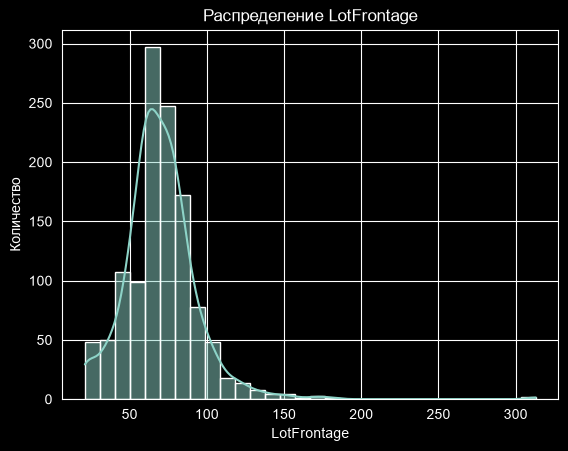

In [2600]:
plt.figure()
sns.histplot(df['LotFrontage'], kde=True, bins=30)
plt.title('Распределение LotFrontage')
plt.xlabel('LotFrontage')
plt.ylabel('Количество')
plt.show()

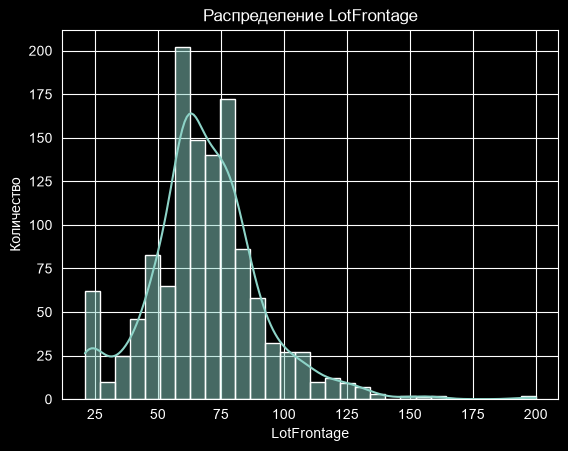

In [2601]:
plt.figure()
sns.histplot(df_test['LotFrontage'], kde=True, bins=30)
plt.title('Распределение LotFrontage')
plt.xlabel('LotFrontage')
plt.ylabel('Количество')
plt.show()

In [2602]:
upper_limit = 200

df['LotFrontage'] = df['LotFrontage'].clip(upper=upper_limit)
df_test['LotFrontage'] = df_test['LotFrontage'].clip(upper=upper_limit)

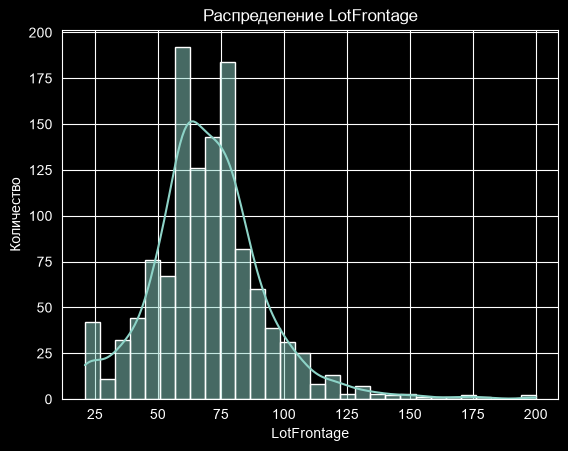

In [2603]:
plt.figure()
sns.histplot(df['LotFrontage'], kde=True, bins=30)
plt.title('Распределение LotFrontage')
plt.xlabel('LotFrontage')
plt.ylabel('Количество')
plt.show()

In [2604]:
med_l1 = df.groupby(['Neighborhood', 'LotConfig'])['LotFrontage'].median()
med_l2 = df.groupby('Neighborhood')['LotFrontage'].median()
med_global = df['LotFrontage'].median()

l1_train = pd.Series(df.set_index(['Neighborhood', 'LotConfig']).index.map(med_l1), index=df.index)
l2_train = df['Neighborhood'].map(med_l2)
df['LotFrontage'] = df['LotFrontage'].fillna(l1_train).fillna(l2_train).fillna(med_global)

l1_test = pd.Series(df_test.set_index(['Neighborhood', 'LotConfig']).index.map(med_l1), index=df_test.index)
l2_test = df_test['Neighborhood'].map(med_l2)
df_test['LotFrontage'] = df_test['LotFrontage'].fillna(l1_test).fillna(l2_test).fillna(med_global)

In [2605]:
print(df['LotFrontage'].isnull().sum())
print(df_test['LotFrontage'].isnull().sum())

0
0


LotArea

In [2606]:
print(df['LotArea'].isnull().sum())
print(df_test['LotArea'].isnull().sum())

0
0


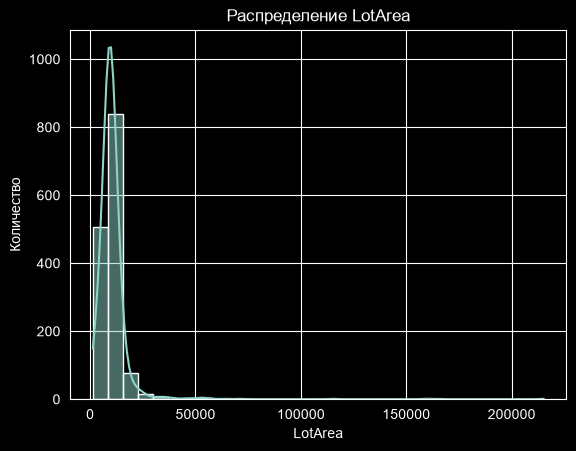

In [2607]:
plt.figure()
sns.histplot(df['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

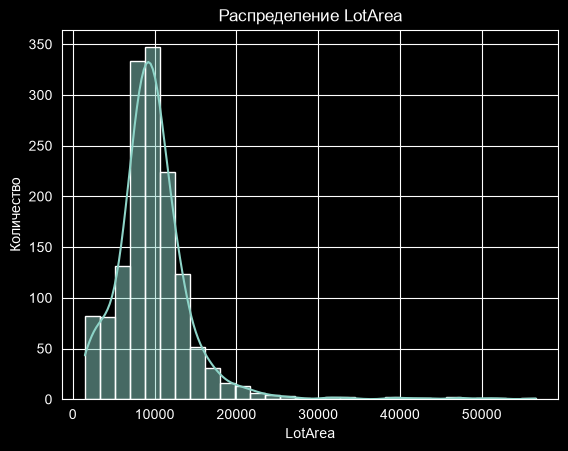

In [2608]:
plt.figure()
sns.histplot(df_test['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

In [2609]:
df['LotArea'] = np.log1p(df['LotArea'])
df_test['LotArea'] = np.log1p(df_test['LotArea'])

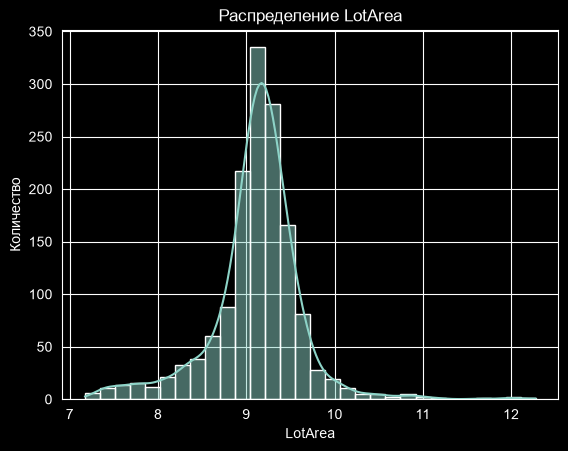

In [2610]:
plt.figure()
sns.histplot(df['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

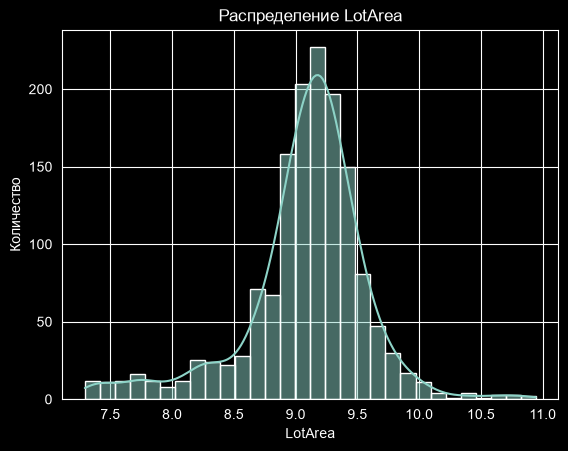

In [2611]:
plt.figure()
sns.histplot(df_test['LotArea'], kde=True, bins=30)
plt.title('Распределение LotArea')
plt.xlabel('LotArea')
plt.ylabel('Количество')
plt.show()

Street

In [2612]:
print(df['Street'].isnull().sum())
print(df_test['Street'].isnull().sum())

0
0


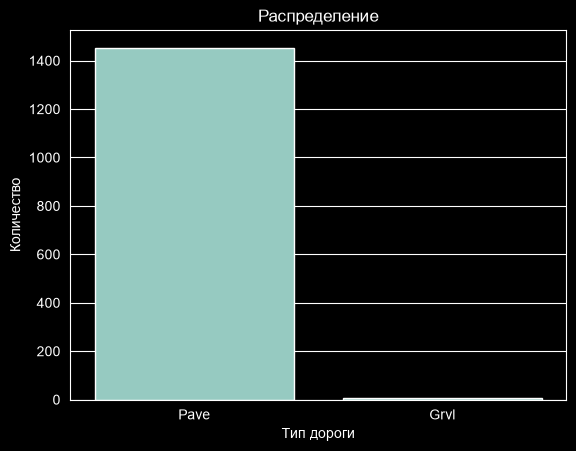

In [2613]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.countplot(data=df, x='Street')
plt.title('Распределение')
plt.xlabel('Тип дороги')
plt.ylabel('Количество')
plt.show()

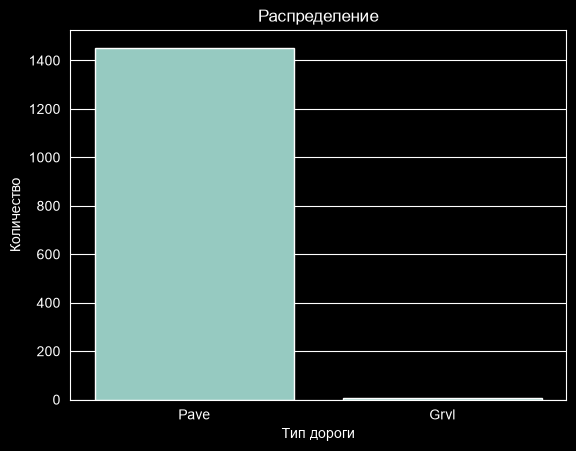

In [2614]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.countplot(data=df_test, x='Street')
plt.title('Распределение')
plt.xlabel('Тип дороги')
plt.ylabel('Количество')
plt.show()

In [2615]:
print(df['Street'].value_counts(dropna=False))
print(df_test['Street'].value_counts(dropna=False))

Street
Pave    1454
Grvl       6
Name: count, dtype: int64
Street
Pave    1453
Grvl       6
Name: count, dtype: int64


признак лучше всего просто дропнуть

In [2616]:
df = df.drop(columns=['Street'])
df_test = df_test.drop(columns=['Street'])

Alley

In [2617]:
print(df['Alley'].isnull().sum())
print(df_test['Alley'].isnull().sum())

1369
1352


In [2618]:
df['Alley'] = df['Alley'].fillna("None")
df_test['Alley'] = df_test['Alley'].fillna("None")

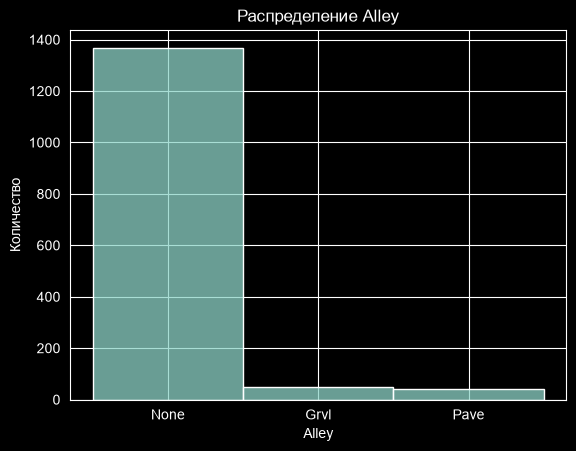

In [2619]:
plt.figure()
sns.histplot(df['Alley'], kde=False, bins=30)
plt.title('Распределение Alley')
plt.xlabel('Alley')
plt.ylabel('Количество')
plt.show()

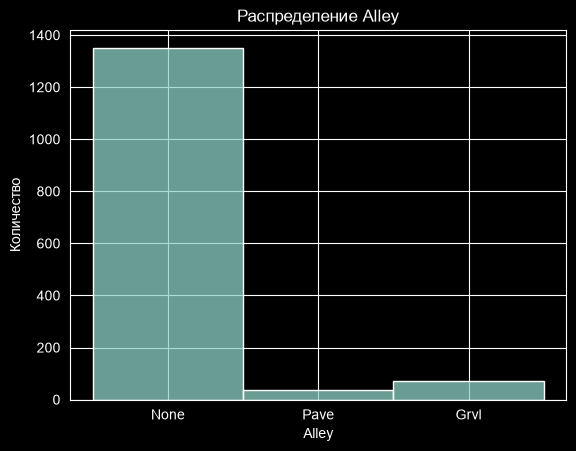

In [2620]:
plt.figure()
sns.histplot(df_test['Alley'], kde=False, bins=30)
plt.title('Распределение Alley')
plt.xlabel('Alley')
plt.ylabel('Количество')
plt.show()

LotShape


In [2621]:
print(df['LotShape'].isnull().sum())
print(df_test['LotShape'].isnull().sum())

0
0


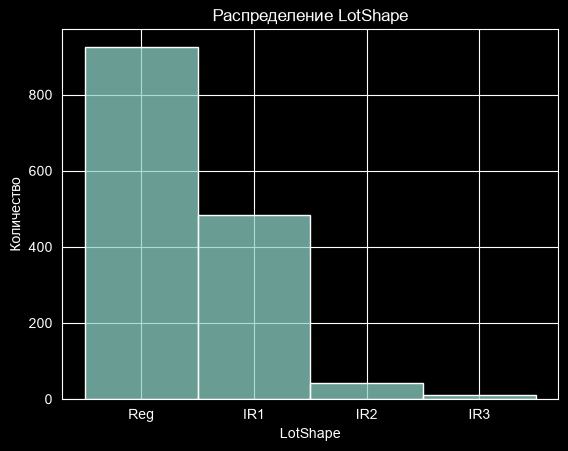

In [2622]:
plt.figure()
sns.histplot(df['LotShape'], kde=False, bins=30)
plt.title('Распределение LotShape')
plt.xlabel('LotShape')
plt.ylabel('Количество')
plt.show()

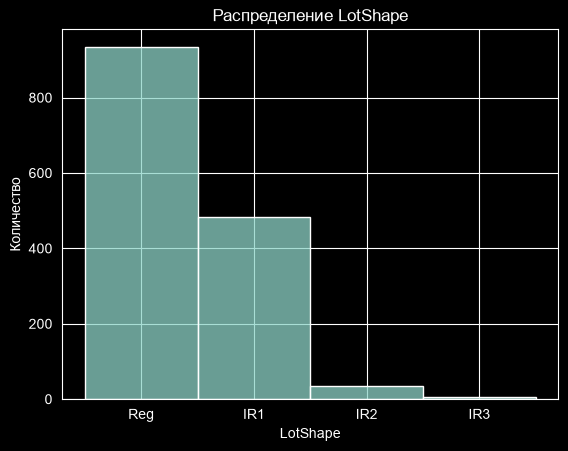

In [2623]:
plt.figure()
sns.histplot(df_test['LotShape'], kde=False, bins=30)
plt.title('Распределение LotShape')
plt.xlabel('LotShape')
plt.ylabel('Количество')
plt.show()

LandContour

In [2624]:
print(df['LandContour'].isnull().sum())
print(df_test['LandContour'].isnull().sum())

0
0


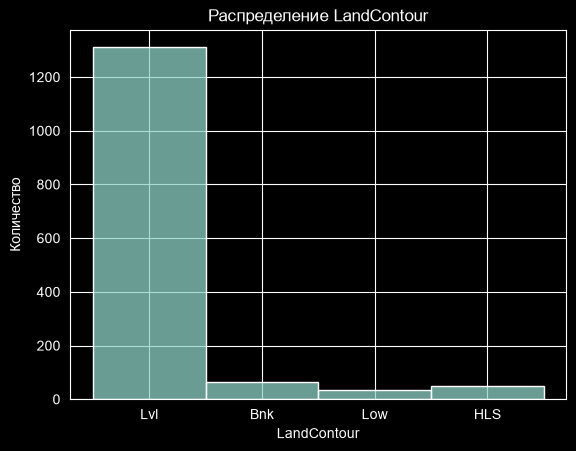

In [2625]:
plt.figure()
sns.histplot(df['LandContour'], kde=False, bins=30)
plt.title('Распределение LandContour')
plt.xlabel('LandContour')
plt.ylabel('Количество')
plt.show()

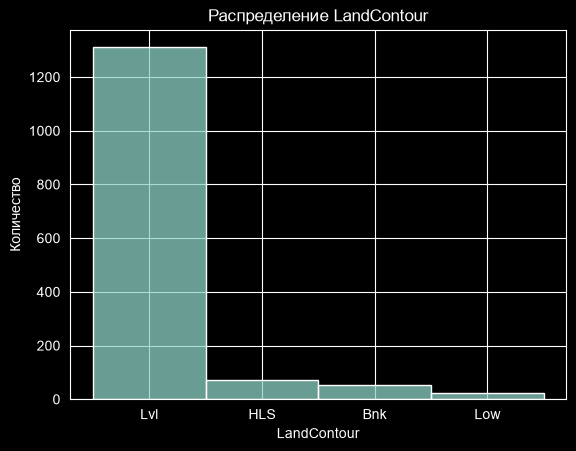

In [2626]:
plt.figure()
sns.histplot(df_test['LandContour'], kde=False, bins=30)
plt.title('Распределение LandContour')
plt.xlabel('LandContour')
plt.ylabel('Количество')
plt.show()

Utilities

In [2627]:
print(df['Utilities'].isnull().sum())
print(df_test['Utilities'].isnull().sum())

0
2


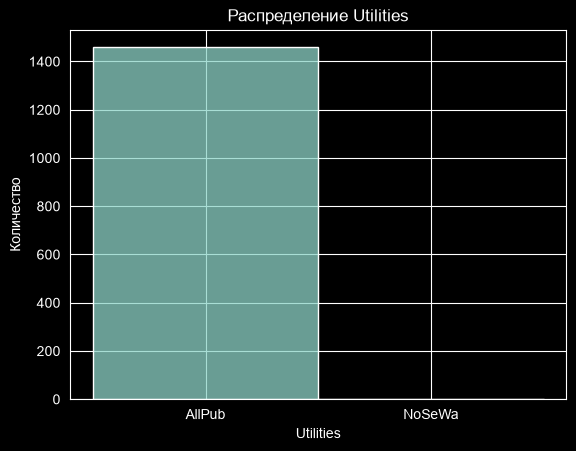

In [2628]:
plt.figure()
sns.histplot(df['Utilities'], kde=False, bins=30)
plt.title('Распределение Utilities')
plt.xlabel('Utilities')
plt.ylabel('Количество')
plt.show()

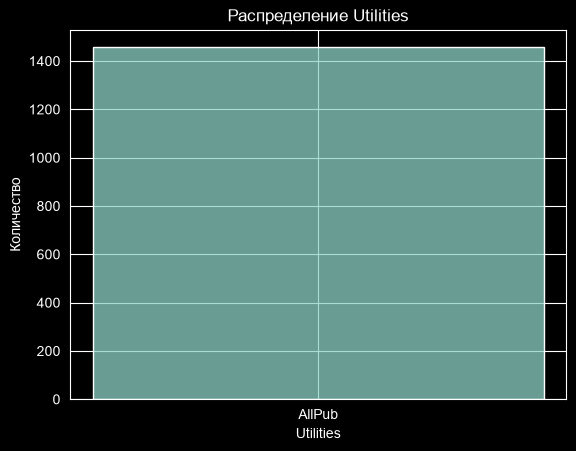

In [2629]:
plt.figure()
sns.histplot(df_test['Utilities'], kde=False, bins=30)
plt.title('Распределение Utilities')
plt.xlabel('Utilities')
plt.ylabel('Количество')
plt.show()

In [2630]:
df_test['Utilities'].describe()

count       1457
unique         1
top       AllPub
freq        1457
Name: Utilities, dtype: object

In [2631]:
df = df.drop(columns=['Utilities'])
df_test = df_test.drop(columns=['Utilities'])

LotConfig

In [2632]:
print(df['LotConfig'].isnull().sum())
print(df_test['LotConfig'].isnull().sum())

0
0


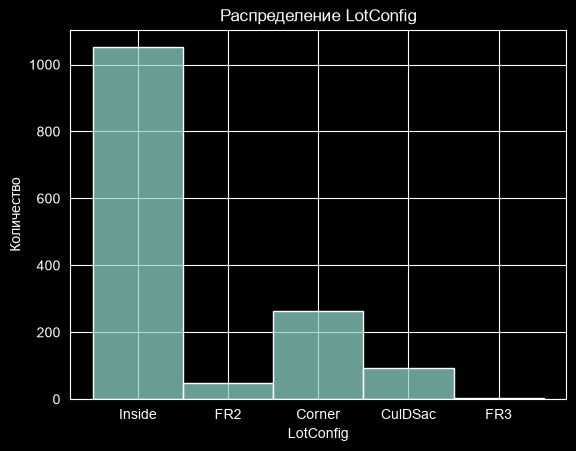

In [2633]:
plt.figure()
sns.histplot(df['LotConfig'], kde=False, bins=30)
plt.title('Распределение LotConfig')
plt.xlabel('LotConfig')
plt.ylabel('Количество')
plt.show()

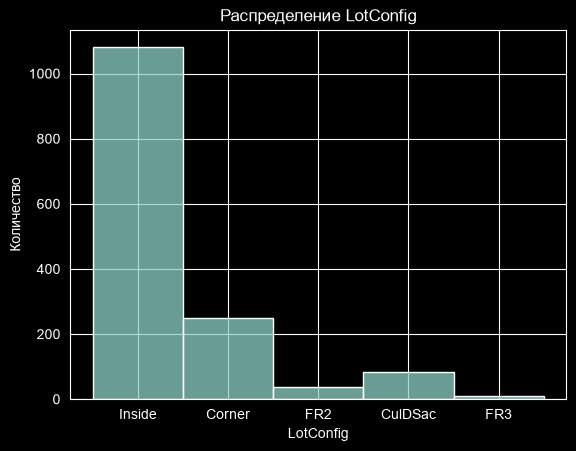

In [2634]:
plt.figure()
sns.histplot(df_test['LotConfig'], kde=False, bins=30)
plt.title('Распределение LotConfig')
plt.xlabel('LotConfig')
plt.ylabel('Количество')
plt.show()

In [2635]:
df['LotConfig'].value_counts()

LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

In [2636]:
df_test['LotConfig'].value_counts()

LotConfig
Inside     1081
Corner      248
CulDSac      82
FR2          38
FR3          10
Name: count, dtype: int64

In [2637]:
df['LotConfig'] = df['LotConfig'].replace({'FR2': 'FR', 'FR3': 'FR'})
df_test['LotConfig'] = df_test['LotConfig'].replace({'FR2': 'FR', 'FR3': 'FR'})

LandSlope

In [2638]:
print(df['LandSlope'].isnull().sum())
print(df_test['LandSlope'].isnull().sum())

0
0


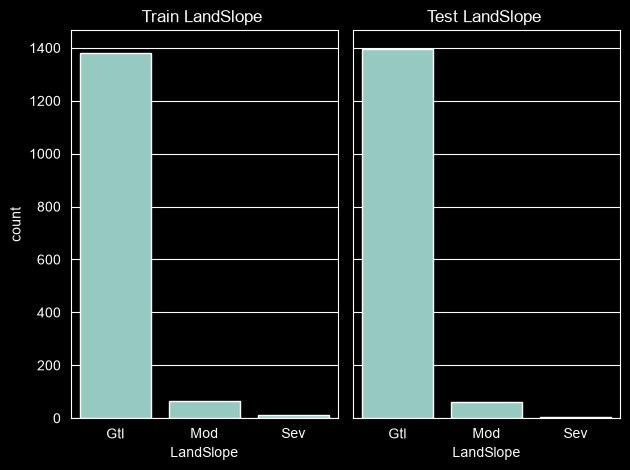

In [2639]:
fig, axes = plt.subplots(1, 2, sharey=True)

sns.countplot(data=df, x='LandSlope', ax=axes[0])
axes[0].set_title('Train LandSlope ')

sns.countplot(data=df_test, x='LandSlope', ax=axes[1])
axes[1].set_title('Test LandSlope ')

plt.tight_layout()
plt.show()

Neighborhood

In [2640]:
print(df['Neighborhood'].isnull().sum())
print(df_test['Neighborhood'].isnull().sum())

0
0


C:\Users\wany0\AppData\Local\Temp\ipykernel_6612\2533215671.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
C:\Users\wany0\AppData\Local\Temp\ipykernel_6612\2533215671.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


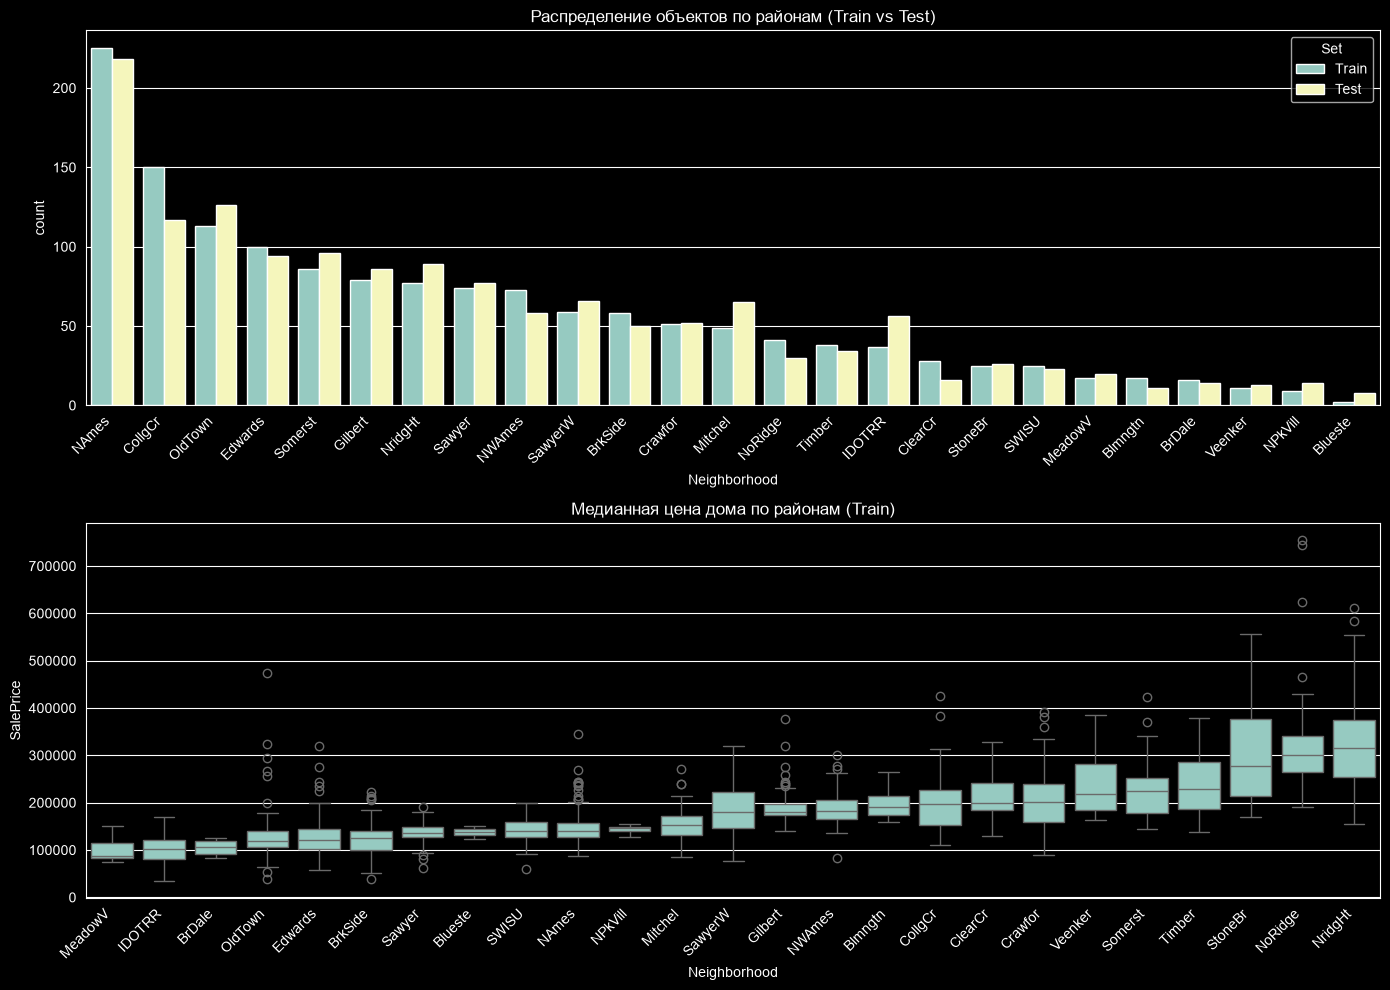

In [2641]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

combined = pd.concat([
    df[['Neighborhood']].assign(Set='Train'),
    df_test[['Neighborhood']].assign(Set='Test')
])
sns.countplot(data=combined, x='Neighborhood', hue='Set', ax=axes[0], order=df['Neighborhood'].value_counts().index)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_title('Распределение объектов по районам (Train vs Test)')

order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', ax=axes[1], order=order)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_title('Медианная цена дома по районам (Train)')

plt.tight_layout()
plt.show()

Condition1

In [2642]:
print(df['Condition1'].isnull().sum())
print(df_test['Condition1'].isnull().sum())

0
0


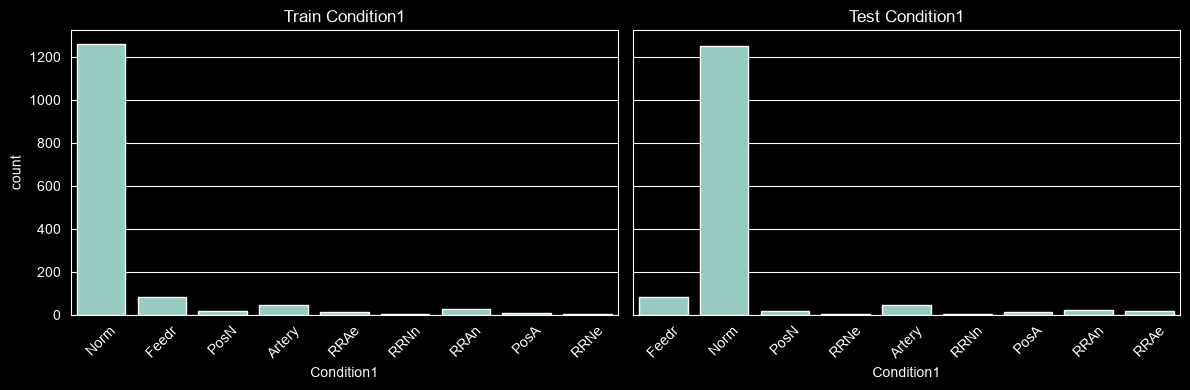

In [2643]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Condition1', ax=axes[0])
axes[0].set_title('Train Condition1')

sns.countplot(data=df_test, x='Condition1', ax=axes[1])
axes[1].set_title('Test Condition1')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Condition2

In [2644]:
print(df['Condition2'].isnull().sum())
print(df_test['Condition2'].isnull().sum())

0
0


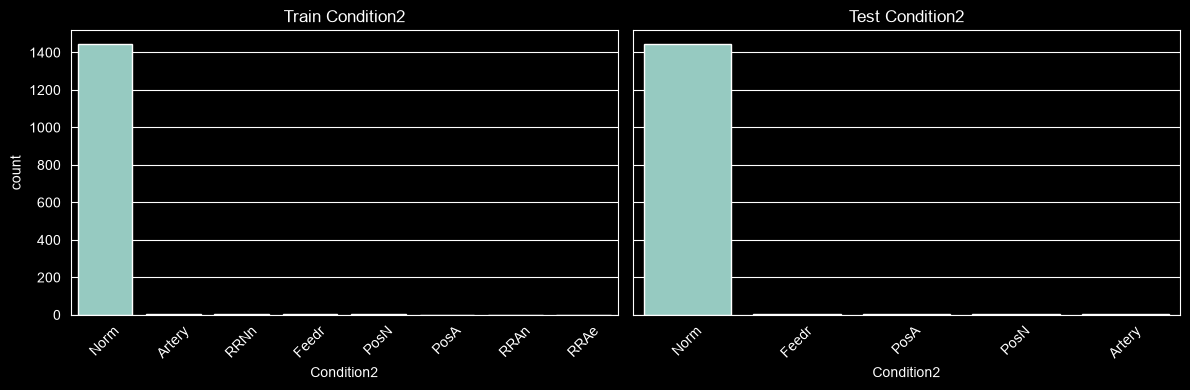

In [2645]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Condition2', ax=axes[0])
axes[0].set_title('Train Condition2')

sns.countplot(data=df_test, x='Condition2', ax=axes[1])
axes[1].set_title('Test Condition2')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2646]:
railroad = ['RRNn','RRAn','RRNe','RRAe']
street = ['Artery', 'Feedr']
park = ['PosN','PosA']

df['RailRoad'] = (df['Condition1'].isin(railroad) | df['Condition2'].isin(railroad)).astype(int)
df_test['RailRoad'] = (df_test['Condition1'].isin(railroad) | df_test['Condition2'].isin(railroad)).astype(int)

df['NearStreet']= (df['Condition1'].isin(street) | df['Condition2'].isin(street)).astype(int)
df_test['NearStreet'] = (df_test['Condition1'].isin(street) | df_test['Condition2'].isin(street)).astype(int)

df['NearPark']= (df['Condition1'].isin(park) | df['Condition2'].isin(park)).astype(int)
df_test['NearPark'] = (df_test['Condition1'].isin(park) | df_test['Condition2'].isin(park)).astype(int)

df = df.drop(columns=['Condition1','Condition2'])
df_test = df_test.drop(columns=['Condition1','Condition2'])



BldgType

In [2647]:
print(df['BldgType'].isnull().sum())
print(df_test['BldgType'].isnull().sum())

0
0


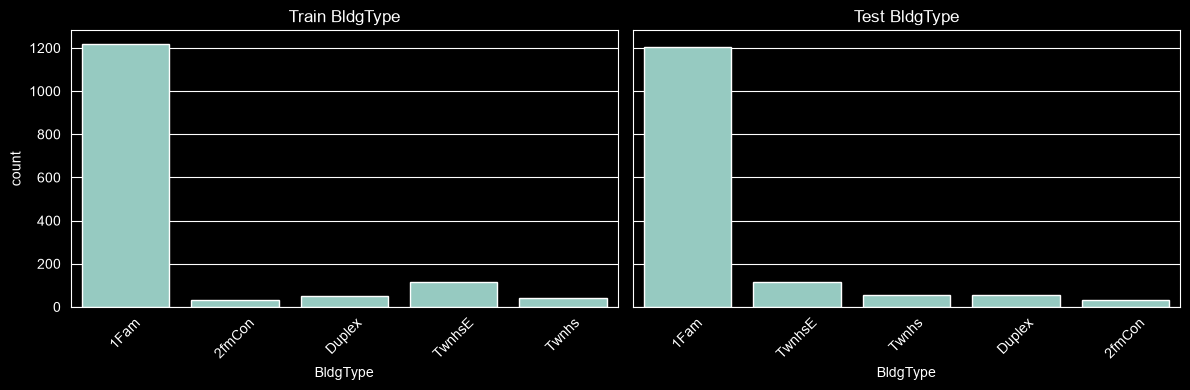

In [2648]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='BldgType', ax=axes[0])
axes[0].set_title('Train BldgType')

sns.countplot(data=df_test, x='BldgType', ax=axes[1])
axes[1].set_title('Test BldgType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

HouseStyle

In [2649]:
print(df['HouseStyle'].isnull().sum())
print(df_test['HouseStyle'].isnull().sum())

0
0


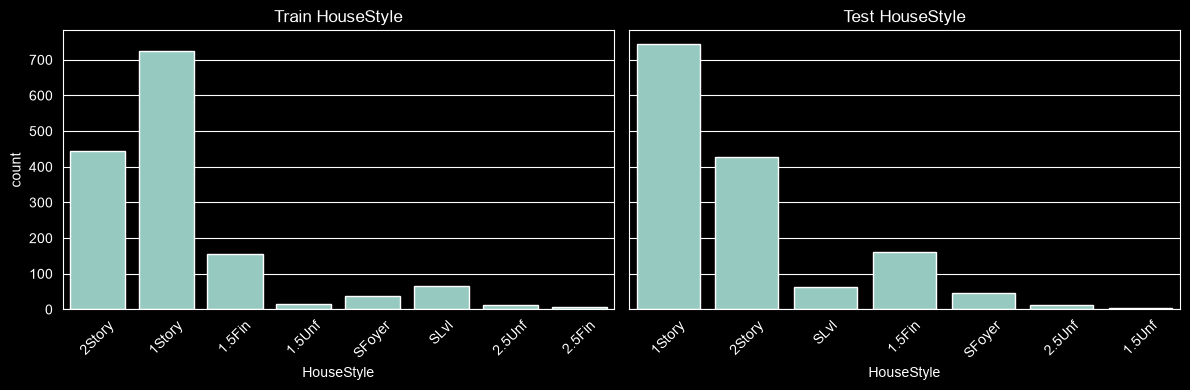

In [2650]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='HouseStyle', ax=axes[0])
axes[0].set_title('Train HouseStyle')

sns.countplot(data=df_test, x='HouseStyle', ax=axes[1])
axes[1].set_title('Test HouseStyle')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2651]:
style_map = {
    '1Story': '1Story',
    '1.5Fin': '1.5Story',
    '1.5Unf': '1.5Story',
    '2Story': '2Story',
    '2.5Fin': '2.5Story',
    '2.5Unf': '2.5Story',
    'SFoyer': 'Split',
    'SLvl': 'Split'
}

df['HouseStyle_Group'] = df['HouseStyle'].map(style_map)
df_test['HouseStyle_Group'] = df_test['HouseStyle'].map(style_map)
df = df.drop(columns=['HouseStyle'])
df_test = df_test.drop(columns=['HouseStyle'])

OverallQual

In [2652]:
print(df['OverallQual'].isnull().sum())
print(df_test['OverallQual'].isnull().sum())

0
0


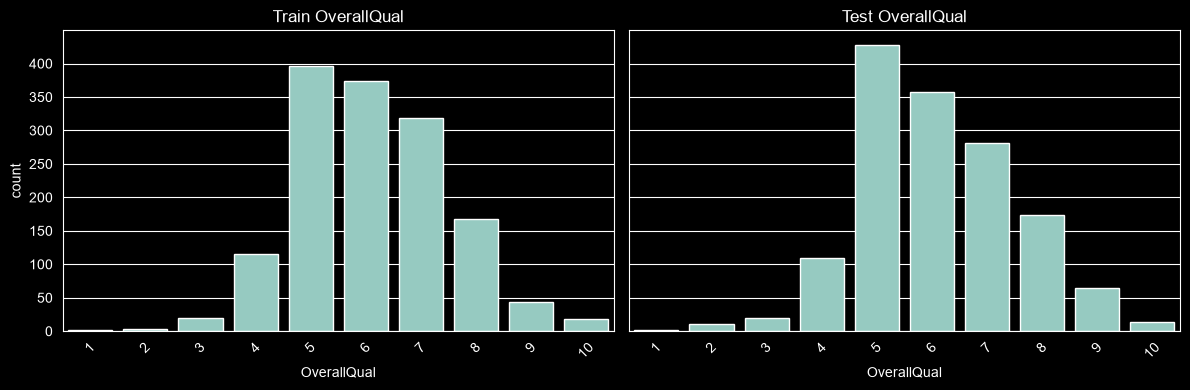

In [2653]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='OverallQual', ax=axes[0])
axes[0].set_title('Train OverallQual')

sns.countplot(data=df_test, x='OverallQual', ax=axes[1])
axes[1].set_title('Test OverallQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

OverallCond

In [2654]:
print(df['OverallCond'].isnull().sum())
print(df_test['OverallCond'].isnull().sum())

0
0


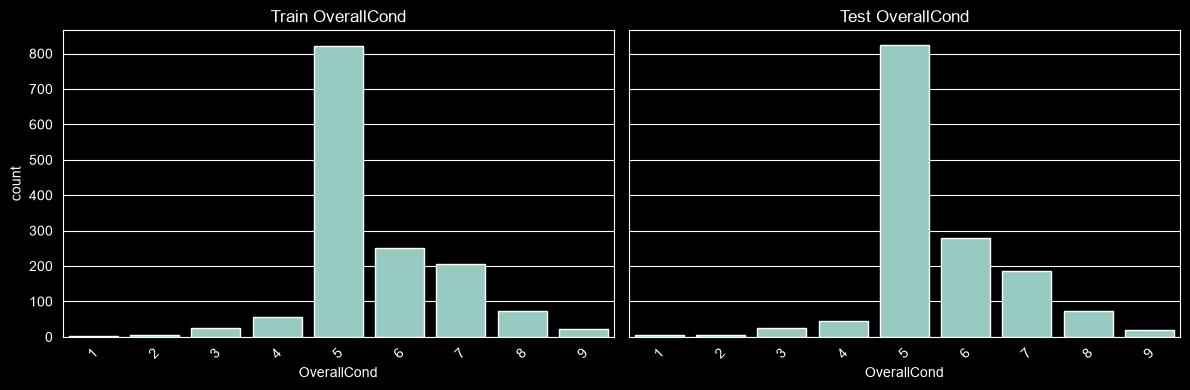

In [2655]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='OverallCond', ax=axes[0])
axes[0].set_title('Train OverallCond')

sns.countplot(data=df_test, x='OverallCond', ax=axes[1])
axes[1].set_title('Test OverallCond')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

YearBuilt + YearRemodAdd + YrSold

In [2656]:
def process_garage_block(df_in, stats=None):
    data = df_in.copy()
    cat_cols = ["GarageFinish", "GarageQual", "GarageCond"]

    no_garage = data["GarageType"].isna()
    data.loc[no_garage, ["GarageCars", "GarageArea"]] = 0
    data.loc[no_garage, "GarageYrBlt"] = 0
    data.loc[no_garage, "GarageType"] = "None"
    for col in cat_cols:
        data.loc[no_garage, col] = "None"

    has_garage = data["GarageType"] != "None"

    if stats is None:
        present = data.loc[has_garage]
        stats = {
            "cars_by_type": present.groupby("GarageType")["GarageCars"].median(),
            "area_by_type": present.groupby("GarageType")["GarageArea"].median(),
            "cars_global": present["GarageCars"].median(),
            "area_global": present["GarageArea"].median(),
        }
        for col in cat_cols:
            stats[col] = present[col].mode(dropna=True).iloc[0]

    data.loc[has_garage, "GarageCars"] = (
        data.loc[has_garage, "GarageCars"]
        .fillna(data.loc[has_garage, "GarageType"].map(stats["cars_by_type"]))
        .fillna(stats["cars_global"])
    )
    data.loc[has_garage, "GarageArea"] = (
        data.loc[has_garage, "GarageArea"]
        .fillna(data.loc[has_garage, "GarageType"].map(stats["area_by_type"]))
        .fillna(stats["area_global"])
    )

    missing_year = has_garage & data["GarageYrBlt"].isna()
    data.loc[missing_year, "GarageYrBlt"] = data.loc[missing_year, "YearBuilt"]
    bad_year = has_garage & (data["GarageYrBlt"] > data["YrSold"])
    data.loc[bad_year, "GarageYrBlt"] = data.loc[bad_year, "YearBuilt"]

    for col in cat_cols:
        data.loc[has_garage, col] = data.loc[has_garage, col].fillna(stats[col])

    data["Area_Per_Car"] = np.where(
        data["GarageCars"] > 0,
        data["GarageArea"] / data["GarageCars"],
        0,
    )
    return data, stats


df, garage_stats = process_garage_block(df)
df_test, _ = process_garage_block(df_test, stats=garage_stats)

In [2657]:
print(df['YearBuilt'].isnull().sum())
print(df_test['YearBuilt'].isnull().sum())

0
0


In [2658]:
df['House_Age'] = np.maximum(0, df['YrSold'] - df['YearBuilt'])
df_test['House_Age'] = np.maximum(0, df_test['YrSold'] - df_test['YearBuilt'])

df['Remod_Age'] = np.maximum(0, df['YrSold'] - df['YearRemodAdd'])
df_test['Remod_Age'] = np.maximum(0, df_test['YrSold'] - df_test['YearRemodAdd'])

df['Is_Remodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
df_test['Is_Remodeled'] = (df_test['YearRemodAdd'] != df_test['YearBuilt']).astype(int)

df['Age_At_Remod'] = df['YearRemodAdd'] - df['YearBuilt']
df_test['Age_At_Remod'] = df_test['YearRemodAdd'] - df_test['YearBuilt']

cols_to_drop = ['YearBuilt', 'YearRemodAdd']

df = df.drop(columns=cols_to_drop)
df_test = df_test.drop(columns=cols_to_drop)

RoofStyle

In [2659]:
print(df['RoofStyle'].isnull().sum())
print(df_test['RoofStyle'].isnull().sum())

0
0


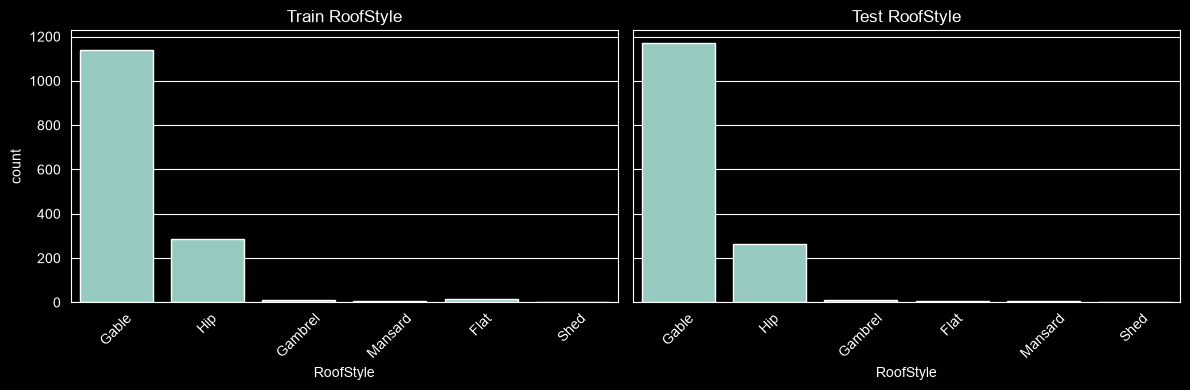

In [2660]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='RoofStyle', ax=axes[0])
axes[0].set_title('Train RoofStyle')

sns.countplot(data=df_test, x='RoofStyle', ax=axes[1])
axes[1].set_title('Test RoofStyle')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2661]:
roof_map = {
    'Gable': 'Gable',
    'Hip': 'Hip'
}

df['RoofStyle'] = df['RoofStyle'].map(roof_map).fillna('Other')
df_test['RoofStyle'] = df_test['RoofStyle'].map(roof_map).fillna('Other')

RoofMatl

In [2662]:
print(df['RoofMatl'].isnull().sum())
print(df_test['RoofMatl'].isnull().sum())

0
0


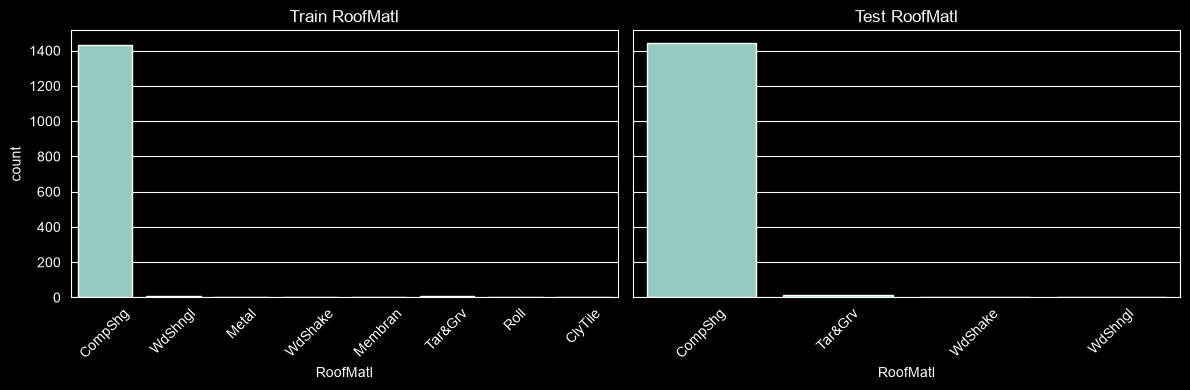

In [2663]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='RoofMatl', ax=axes[0])
axes[0].set_title('Train RoofMatl')

sns.countplot(data=df_test, x='RoofMatl', ax=axes[1])
axes[1].set_title('Test RoofMatl')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2664]:
df = df.drop(columns=['RoofMatl'])
df_test = df_test.drop(columns=['RoofMatl'])

Exterior1st

In [2665]:
print(df['Exterior1st'].isnull().sum())
print(df_test['Exterior1st'].isnull().sum())

0
1


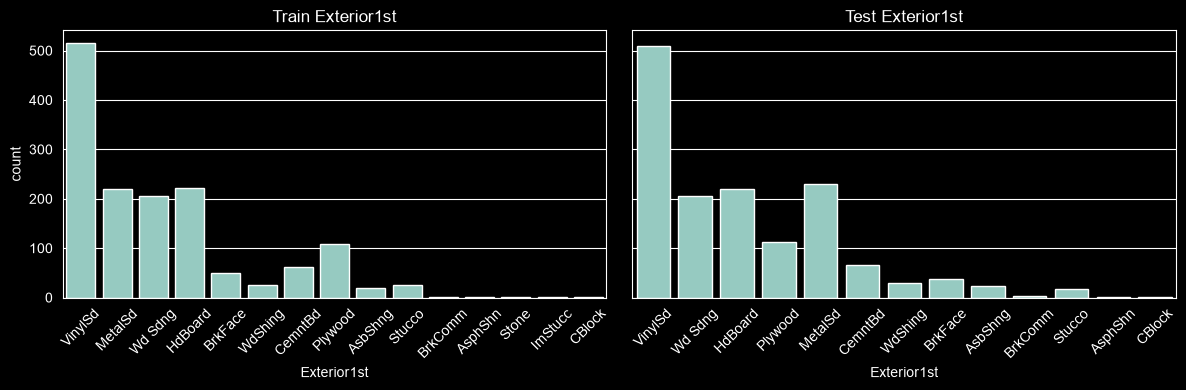

In [2666]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Exterior1st', ax=axes[0])
axes[0].set_title('Train Exterior1st')

sns.countplot(data=df_test, x='Exterior1st', ax=axes[1])
axes[1].set_title('Test Exterior1st')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Exterior2nd

In [2667]:
print(df['Exterior2nd'].isnull().sum())
print(df_test['Exterior2nd'].isnull().sum())

0
1


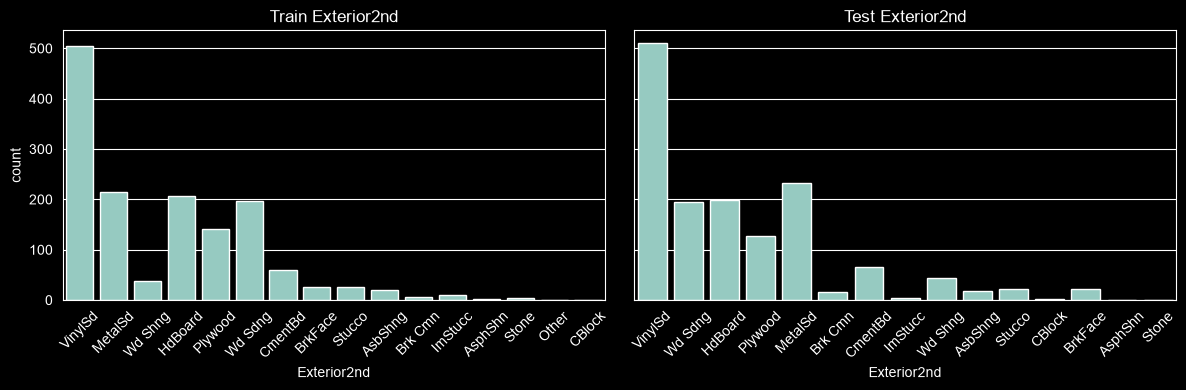

In [2668]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Exterior2nd', ax=axes[0])
axes[0].set_title('Train Exterior2nd')

sns.countplot(data=df_test, x='Exterior2nd', ax=axes[1])
axes[1].set_title('Test Exterior2nd')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2669]:
ext1_global_mode = df['Exterior1st'].mode()[0]
ext2_global_mode = df['Exterior2nd'].mode()[0]

ext1_neigh_mode = df.groupby('Neighborhood')['Exterior1st'].agg(
    lambda x: x.mode()[0] if not x.mode().empty else ext1_global_mode
)
ext2_neigh_mode = df.groupby('Neighborhood')['Exterior2nd'].agg(
    lambda x: x.mode()[0] if not x.mode().empty else ext2_global_mode
)

df_test['Exterior1st'] = df_test['Exterior1st'].fillna(df_test['Neighborhood'].map(ext1_neigh_mode)).fillna(ext1_global_mode)
df_test['Exterior2nd'] = df_test['Exterior2nd'].fillna(df_test['Neighborhood'].map(ext2_neigh_mode)).fillna(ext2_global_mode)

In [2670]:
df['Exterior1st'].unique()

<StringArray>
['VinylSd', 'MetalSd', 'Wd Sdng', 'HdBoard', 'BrkFace', 'WdShing', 'CemntBd',
 'Plywood', 'AsbShng',  'Stucco', 'BrkComm', 'AsphShn',   'Stone', 'ImStucc',
  'CBlock']
Length: 15, dtype: str

In [2671]:
df['Exterior2nd'].unique()

<StringArray>
['VinylSd', 'MetalSd', 'Wd Shng', 'HdBoard', 'Plywood', 'Wd Sdng', 'CmentBd',
 'BrkFace',  'Stucco', 'AsbShng', 'Brk Cmn', 'ImStucc', 'AsphShn',   'Stone',
   'Other',  'CBlock']
Length: 16, dtype: str

In [2672]:
typo_map = {
    'CmentBd': 'CemntBd',
    'Wd Shng': 'WdShing',
    'Brk Cmn': 'BrkComm'
}
df['Exterior2nd'] = df['Exterior2nd'].replace(typo_map)
df_test['Exterior2nd'] = df_test['Exterior2nd'].replace(typo_map)

df['Is_Multiple_Exterior'] = (df['Exterior1st'] != df['Exterior2nd']).astype(int)
df_test['Is_Multiple_Exterior'] = (df_test['Exterior1st'] != df_test['Exterior2nd']).astype(int)

top_materials = ['VinylSd', 'MetalSd', 'HdBoard', 'Wd Sdng', 'Plywood', 'CemntBd', 'WdShing']

df['Exterior1st'] = df['Exterior1st'].apply(lambda x: x if x in top_materials else 'Other')
df_test['Exterior1st'] = df_test['Exterior1st'].apply(lambda x: x if x in top_materials else 'Other')

df['Exterior2nd'] = df['Exterior2nd'].apply(lambda x: x if x in top_materials else 'Other')
df_test['Exterior2nd'] = df_test['Exterior2nd'].apply(lambda x: x if x in top_materials else 'Other')

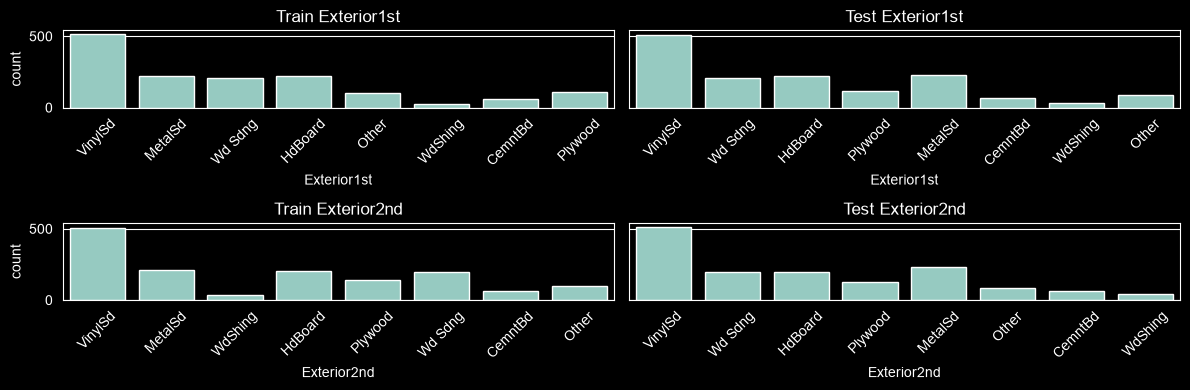

In [2673]:
fig, axes = plt.subplots(2, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Exterior1st', ax=axes[0,0])
axes[0,0].set_title('Train Exterior1st')
sns.countplot(data=df_test, x='Exterior1st', ax=axes[0,1])
axes[0,1].set_title('Test Exterior1st')


sns.countplot(data=df, x='Exterior2nd', ax=axes[1,0])
axes[1,0].set_title('Train Exterior2nd')

sns.countplot(data=df_test, x='Exterior2nd', ax=axes[1,1])
axes[1,1].set_title('Test Exterior2nd')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

MasVnrType + MasVnrArea

In [2674]:
print(df['MasVnrType'].isnull().sum())
print(df_test['MasVnrType'].isnull().sum())

872
894


In [2675]:
print(df['MasVnrArea'].isnull().sum())
print(df_test['MasVnrArea'].isnull().sum())

8
15


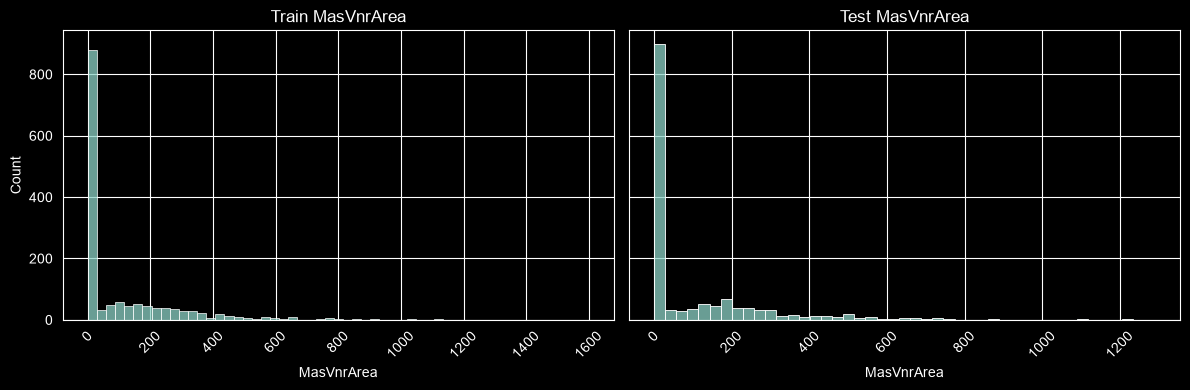

In [2676]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='MasVnrArea', ax=axes[0])
axes[0].set_title('Train MasVnrArea')

sns.histplot(data=df_test, x='MasVnrArea', ax=axes[1])
axes[1].set_title('Test MasVnrArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

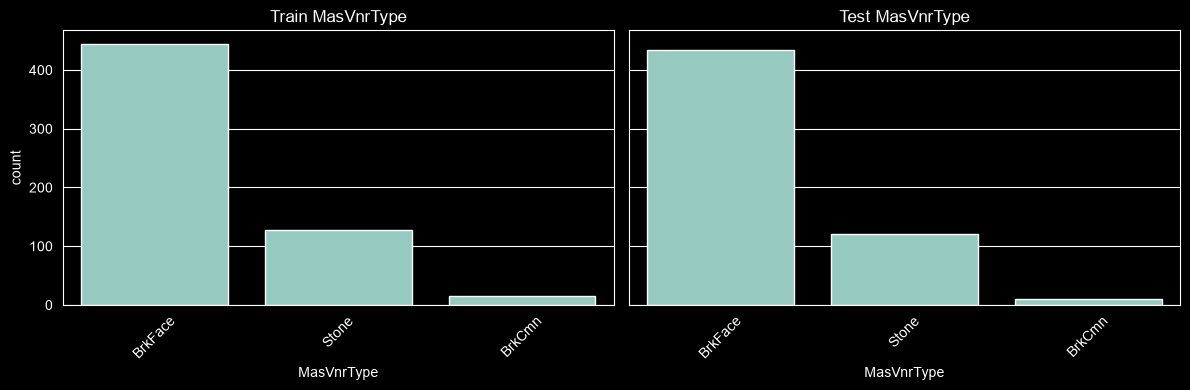

In [2677]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='MasVnrType', ax=axes[0])
axes[0].set_title('Train MasVnrType')

sns.countplot(data=df_test, x='MasVnrType', ax=axes[1])
axes[1].set_title('Test MasVnrType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2678]:
vnr_mode = df.loc[df['MasVnrArea'] > 0, 'MasVnrType'].dropna().mode()[0]

def process_masvnr(data):
    data['MasVnrArea'] = data['MasVnrArea'].fillna(0)
    data['MasVnrType'] = data['MasVnrType'].fillna('None')

    data.loc[data['MasVnrArea'] == 0, 'MasVnrType'] = 'None'
    data.loc[(data['MasVnrArea'] > 0) & (data['MasVnrType'] == 'None'), 'MasVnrType'] = vnr_mode
    data['Has_MasVnr'] = (data['MasVnrArea'] > 0).astype(int)
    return data

df = process_masvnr(df)
df_test = process_masvnr(df_test)

ExterQual

In [2679]:
print(df['ExterQual'].isnull().sum())
print(df_test['ExterQual'].isnull().sum())

0
0


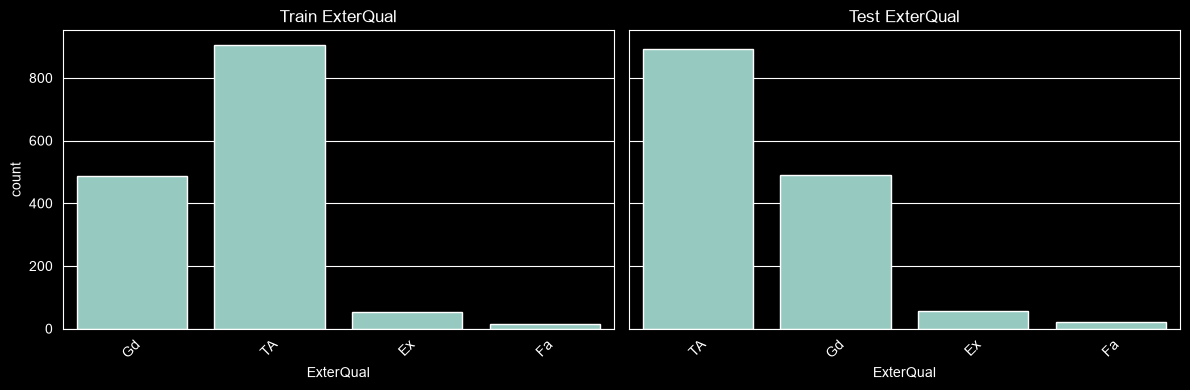

In [2680]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='ExterQual', ax=axes[0])
axes[0].set_title('Train ExterQual')

sns.countplot(data=df_test, x='ExterQual', ax=axes[1])
axes[1].set_title('Test ExterQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

ExterCond

In [2681]:
print(df['ExterCond'].isnull().sum())
print(df_test['ExterCond'].isnull().sum())

0
0


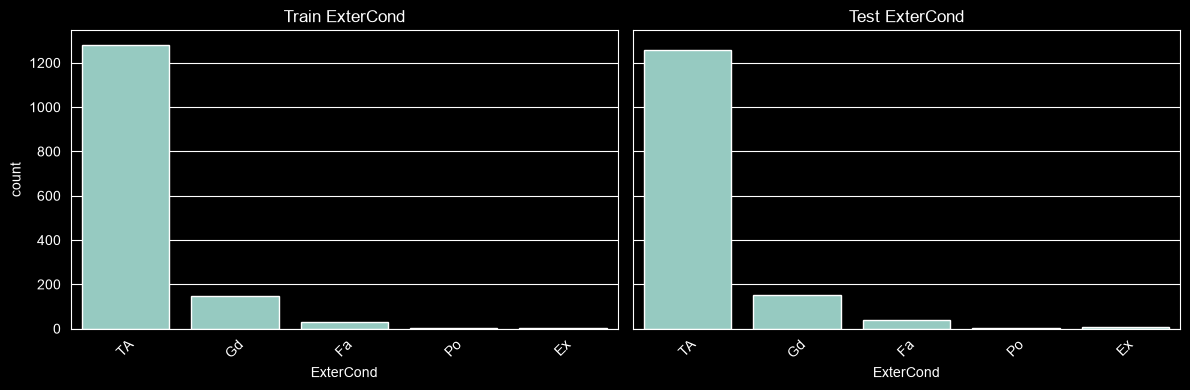

In [2682]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='ExterCond', ax=axes[0])
axes[0].set_title('Train ExterCond')

sns.countplot(data=df_test, x='ExterCond', ax=axes[1])
axes[1].set_title('Test ExterCond')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Foundation

In [2683]:
print(df['Foundation'].isnull().sum())
print(df_test['Foundation'].isnull().sum())

0
0


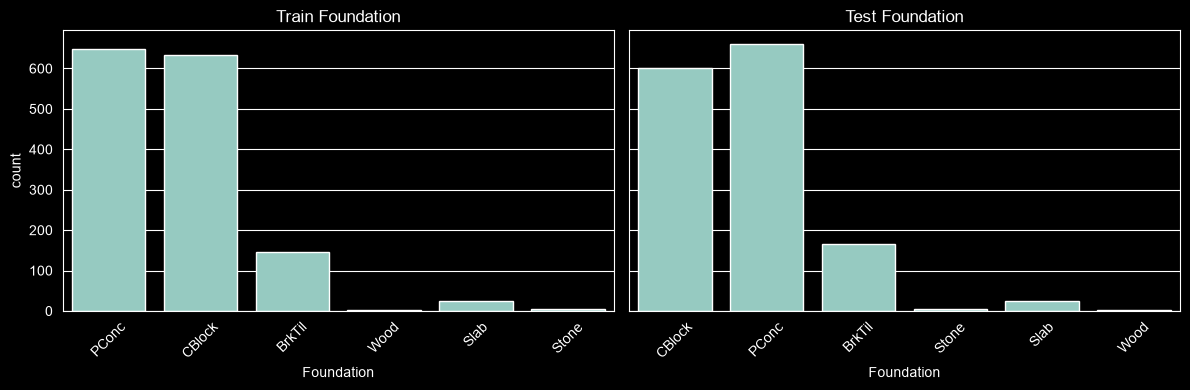

In [2684]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Foundation', ax=axes[0])
axes[0].set_title('Train Foundation')

sns.countplot(data=df_test, x='Foundation', ax=axes[1])
axes[1].set_title('Test Foundation')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Весь подвал(11 фичей подвала это мощно)


In [2685]:
def collapse_bsmt_raw(df_in, stats=None):
    data = df_in.copy()
    num_cols = ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"]
    cat_cols = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

    for col in num_cols:
        data[col] = data[col].fillna(0)

    no_bsmt = data["TotalBsmtSF"] == 0
    for col in cat_cols:
        data.loc[no_bsmt, col] = "None"

    has_bsmt = ~no_bsmt
    if stats is None:
        present = data.loc[has_bsmt]
        stats = {col: present[col].mode(dropna=True).iloc[0] for col in cat_cols}
        second = present.loc[present["BsmtFinSF2"] > 0, "BsmtFinType2"].dropna()
        stats["BsmtFinType2_if_sf2"] = (
            second.mode().iloc[0] if not second.empty else stats["BsmtFinType2"]
        )

    no_second = has_bsmt & data["BsmtFinType2"].isna() & (data["BsmtFinSF2"] == 0)
    data.loc[no_second, "BsmtFinType2"] = "Unf"

    missing_second = has_bsmt & data["BsmtFinType2"].isna() & (data["BsmtFinSF2"] > 0)
    data.loc[missing_second, "BsmtFinType2"] = stats["BsmtFinType2_if_sf2"]

    for col in ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1"]:
        data.loc[has_bsmt, col] = data.loc[has_bsmt, col].fillna(stats[col])

    data["Has_Bsmt"] = has_bsmt.astype(int)
    data["Bsmt_Fin_SF"] = data["BsmtFinSF1"] + data["BsmtFinSF2"]
    data["Bsmt_Baths"] = data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"]
    return data.drop(columns=["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "BsmtFullBath", "BsmtHalfBath"]), stats


df, bsmt_stats = collapse_bsmt_raw(df)
df_test, _ = collapse_bsmt_raw(df_test, stats=bsmt_stats)

Heating

In [2686]:
print(df['Heating'].isnull().sum())
print(df_test['Heating'].isnull().sum())

0
0


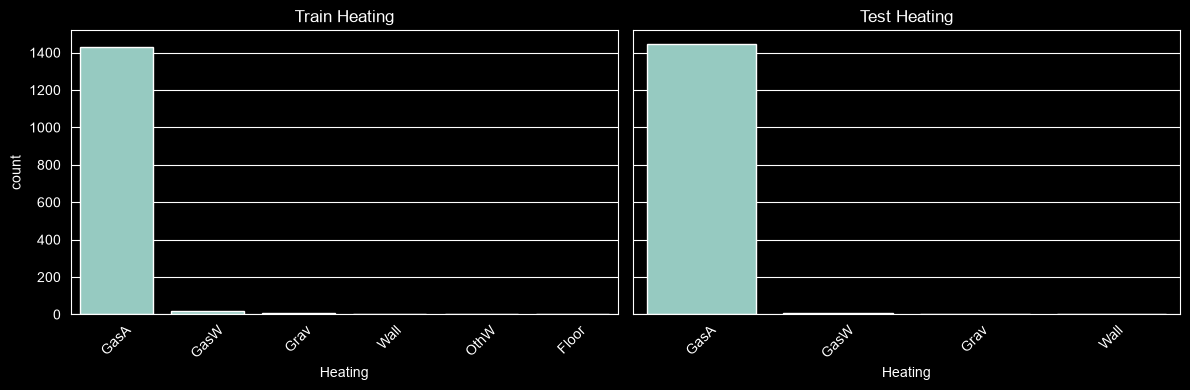

In [2687]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Heating', ax=axes[0])
axes[0].set_title('Train Heating')

sns.countplot(data=df_test, x='Heating', ax=axes[1])
axes[1].set_title('Test Heating')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2688]:
df['Is_GasA'] = (df['Heating'] == 'GasA').astype(int)
df_test['Is_GasA'] = (df_test['Heating'] == 'GasA').astype(int)

df = df.drop(columns=['Heating'])
df_test = df_test.drop(columns=['Heating'])

HeatingQC

In [2689]:
print(df['HeatingQC'].isnull().sum())
print(df_test['HeatingQC'].isnull().sum())

0
0


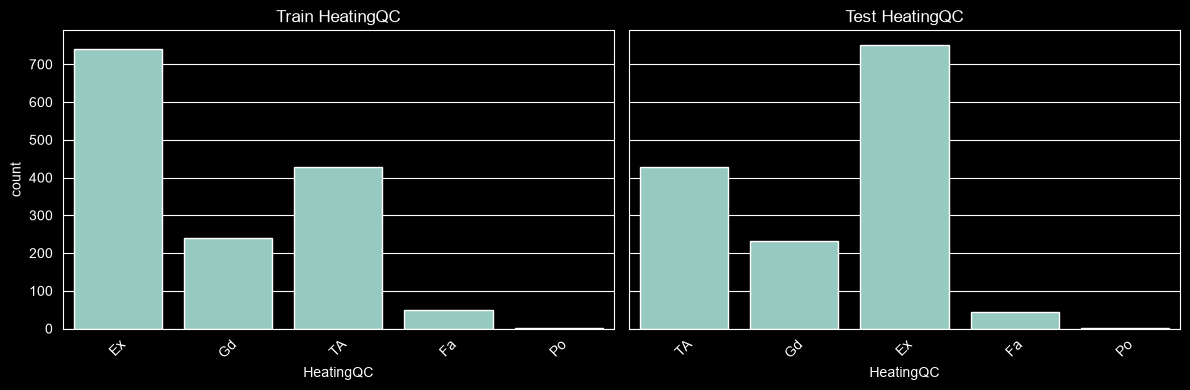

In [2690]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='HeatingQC', ax=axes[0])
axes[0].set_title('Train HeatingQC')

sns.countplot(data=df_test, x='HeatingQC', ax=axes[1])
axes[1].set_title('Test HeatingQC')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

CentralAir

In [2691]:
print(df['CentralAir'].isnull().sum())
print(df_test['CentralAir'].isnull().sum())

0
0


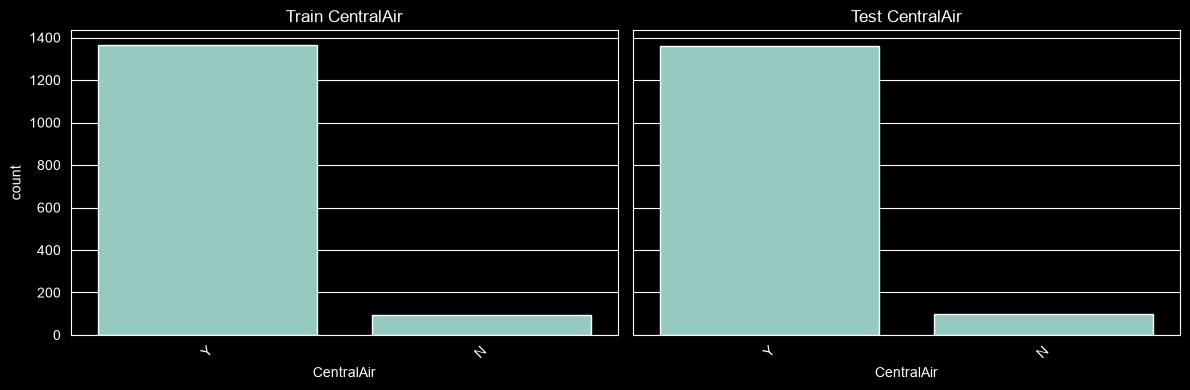

In [2692]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='CentralAir', ax=axes[0])
axes[0].set_title('Train CentralAir')

sns.countplot(data=df_test, x='CentralAir', ax=axes[1])
axes[1].set_title('Test CentralAir')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2693]:
df['CentralAir'] = (df['CentralAir'] == 'Y').astype(int)
df_test['CentralAir'] = (df_test['CentralAir'] == 'Y').astype(int)

Electrical

In [2694]:
print(df['Electrical'].isnull().sum())
print(df_test['Electrical'].isnull().sum())

1
0


In [2695]:
elec_mode = df['Electrical'].mode()[0]

df['Electrical'] = df['Electrical'].fillna(elec_mode)
df_test['Electrical'] = df_test['Electrical'].fillna(elec_mode)


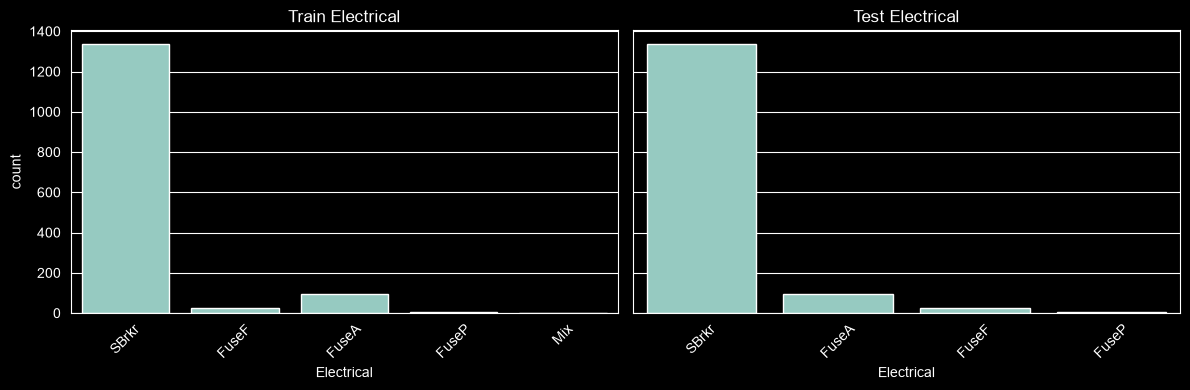

In [2696]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Electrical', ax=axes[0])
axes[0].set_title('Train Electrical')

sns.countplot(data=df_test, x='Electrical', ax=axes[1])
axes[1].set_title('Test Electrical')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2697]:

df['Has_SBrkr'] = (df['Electrical'] == 'SBrkr').astype(int)
df_test['Has_SBrkr'] = (df_test['Electrical'] == 'SBrkr').astype(int)

df = df.drop(columns=['Electrical'])
df_test = df_test.drop(columns=['Electrical'])

1stFlrSF + 2ndFlrSF


In [2698]:
print(df['1stFlrSF'].isnull().sum())
print(df_test['1stFlrSF'].isnull().sum())

0
0


In [2699]:
print(df['2ndFlrSF'].isnull().sum())
print(df_test['2ndFlrSF'].isnull().sum())

0
0


In [2700]:
df['Total_SF'] = df['GrLivArea'] + df['TotalBsmtSF']
df_test['Total_SF'] = df_test['GrLivArea'] + df_test['TotalBsmtSF']

df['Has_2ndFlr'] = (df['2ndFlrSF'] > 0).astype(int)
df_test['Has_2ndFlr'] = (df_test['2ndFlrSF'] > 0).astype(int)



LowQualFinSF

In [2701]:
print(df['LowQualFinSF'].isnull().sum())
print(df_test['LowQualFinSF'].isnull().sum())

0
0


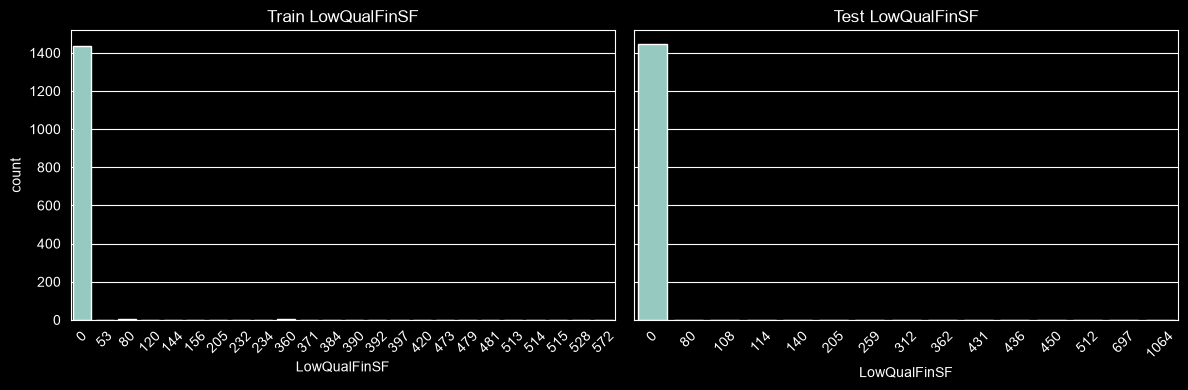

In [2702]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='LowQualFinSF', ax=axes[0])
axes[0].set_title('Train LowQualFinSF')

sns.countplot(data=df_test, x='LowQualFinSF', ax=axes[1])
axes[1].set_title('Test LowQualFinSF')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2703]:
df['Has_LowQualFin'] = (df['LowQualFinSF'] > 0).astype(int)
df_test['Has_LowQualFin'] = (df_test['LowQualFinSF'] > 0).astype(int)

df = df.drop(columns=['LowQualFinSF'])
df_test = df_test.drop(columns=['LowQualFinSF'])

GrLivArea

In [2704]:
print(df['GrLivArea'].isnull().sum())
print(df_test['GrLivArea'].isnull().sum())

0
0


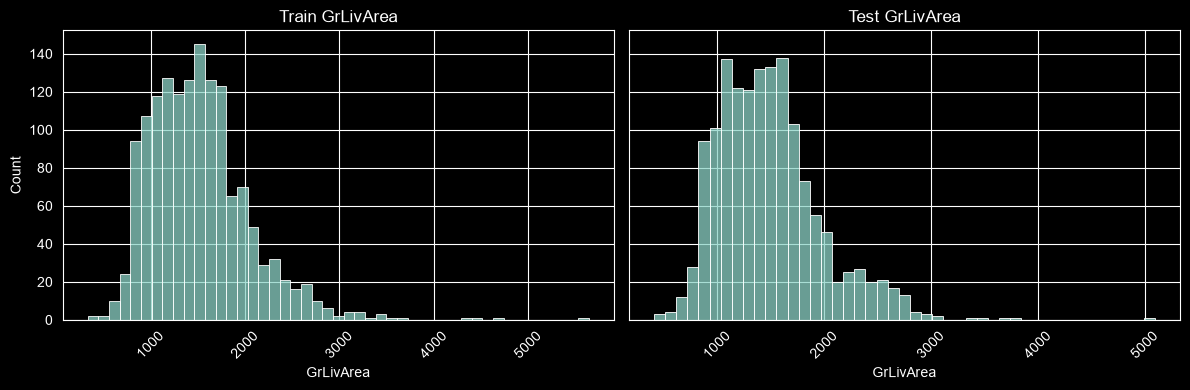

In [2705]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GrLivArea', ax=axes[0])
axes[0].set_title('Train GrLivArea')

sns.histplot(data=df_test, x='GrLivArea', ax=axes[1])
axes[1].set_title('Test GrLivArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

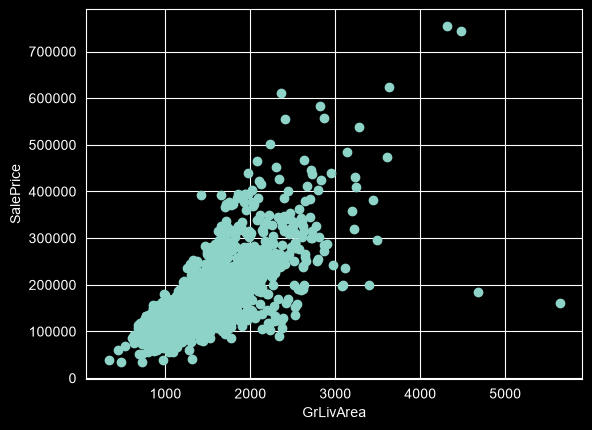

In [2706]:
price = df["SalePrice"].to_numpy(float)
if price.max() < 20:
    price = np.expm1(price)

plt.figure()
plt.scatter(df["GrLivArea"], price)
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.show()


In [2707]:
price = df["SalePrice"].to_numpy(float)
if price.max() < 20:
    price = np.expm1(price)
area = df["GrLivArea"].to_numpy(float)

slope, intercept = np.polyfit(area, price, 1)
resid = price - (slope * area + intercept)
sigma = resid.std(ddof=2)
h = 1 / len(area) + (area - area.mean()) ** 2 / np.sum((area - area.mean()) ** 2)
stud = resid / (sigma * np.sqrt(1 - h))

bad_idx = df.index[stud < -4]
found = df.loc[bad_idx, ["Id", "Neighborhood", "GrLivArea", "SaleCondition", "OverallQual"]].copy()
found["SalePrice"] = price[stud < -4]
print(found)

df = df.drop(index=bad_idx)


        Id Neighborhood  GrLivArea SaleCondition  OverallQual  SalePrice
523    524      Edwards       4676       Partial           10   184750.0
1298  1299      Edwards       5642       Partial           10   160000.0


TotRmsAbvGrd

In [2708]:
print(df['TotRmsAbvGrd'].isnull().sum())
print(df_test['TotRmsAbvGrd'].isnull().sum())

0
0


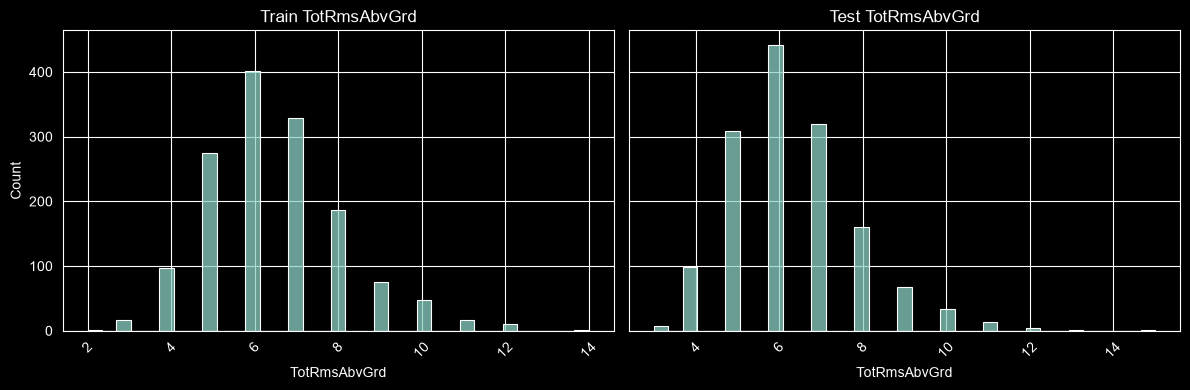

In [2709]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='TotRmsAbvGrd', ax=axes[0])
axes[0].set_title('Train TotRmsAbvGrd')

sns.histplot(data=df_test, x='TotRmsAbvGrd', ax=axes[1])
axes[1].set_title('Test TotRmsAbvGrd')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2710]:
df['Avg_Room_SF'] = df['GrLivArea'] / df['TotRmsAbvGrd']
df_test['Avg_Room_SF'] = df_test['GrLivArea'] / df_test['TotRmsAbvGrd']

FullBath

In [2711]:
print(df['FullBath'].isnull().sum())
print(df_test['FullBath'].isnull().sum())

0
0


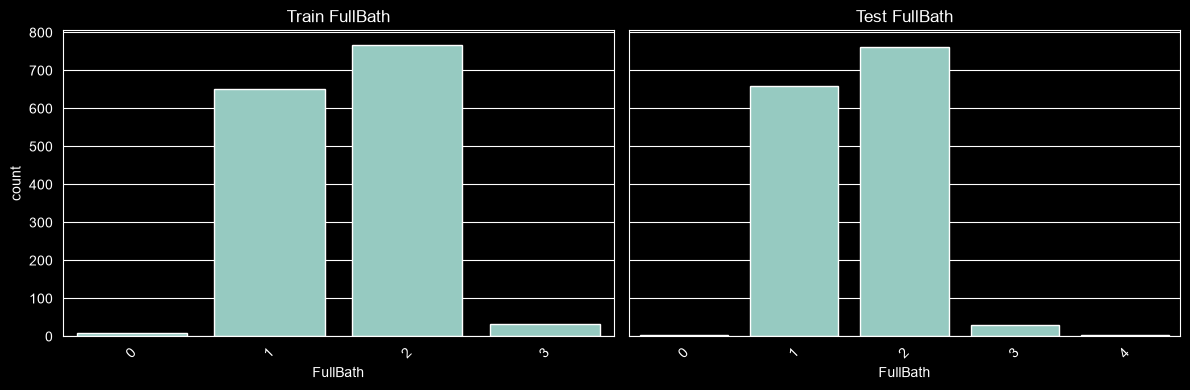

In [2712]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='FullBath', ax=axes[0])
axes[0].set_title('Train FullBath')

sns.countplot(data=df_test, x='FullBath', ax=axes[1])
axes[1].set_title('Test FullBath')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

HalfBath

In [2713]:
print(df['HalfBath'].isnull().sum())
print(df_test['HalfBath'].isnull().sum())

0
0


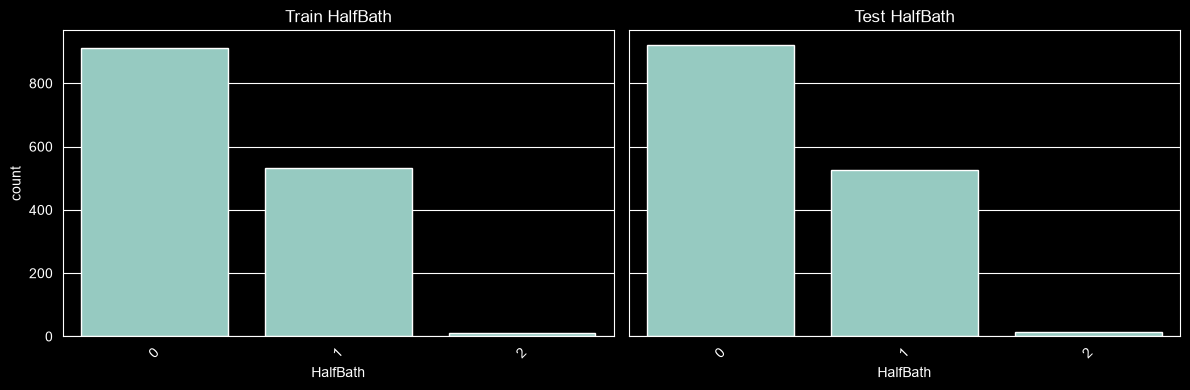

In [2714]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='HalfBath', ax=axes[0])
axes[0].set_title('Train HalfBath')

sns.countplot(data=df_test, x='HalfBath', ax=axes[1])
axes[1].set_title('Test HalfBath')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2715]:
df['AbvGrd_Baths'] = df['FullBath'] + 0.5 * df['HalfBath']
df_test['AbvGrd_Baths'] = df_test['FullBath'] + 0.5 * df_test['HalfBath']

df['Total_Baths'] = df['AbvGrd_Baths'] + df['Bsmt_Baths']
df_test['Total_Baths'] = df_test['AbvGrd_Baths'] + df_test['Bsmt_Baths']

df = df.drop(columns=['FullBath', 'HalfBath'])
df_test = df_test.drop(columns=['FullBath', 'HalfBath'])

Bedroom

In [2716]:
# print(df['Bedroom'].isnull().sum())
# print(df_test['Bedroom'].isnull().sum())

In [2717]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Alley',
       'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood',
       'BldgType', 'OverallQual', 'OverallCond', 'RoofStyle', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond',
       'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
       'BsmtFinType2', 'TotalBsmtSF', 'HeatingQC', 'CentralAir', '1stFlrSF',
       '2ndFlrSF', 'GrLivArea', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC',
       'Fence', 'MiscFeature', 'MiscVal', 'MoSold', 'YrSold', 'SaleType',
       'SaleCondition', 'SalePrice', 'RailRoad', 'NearStreet', 'NearPark',
       'HouseStyl

In [2718]:
print(df['BedroomAbvGr'].isna().sum())
print(df_test['BedroomAbvGr'].isna().sum())

0
0


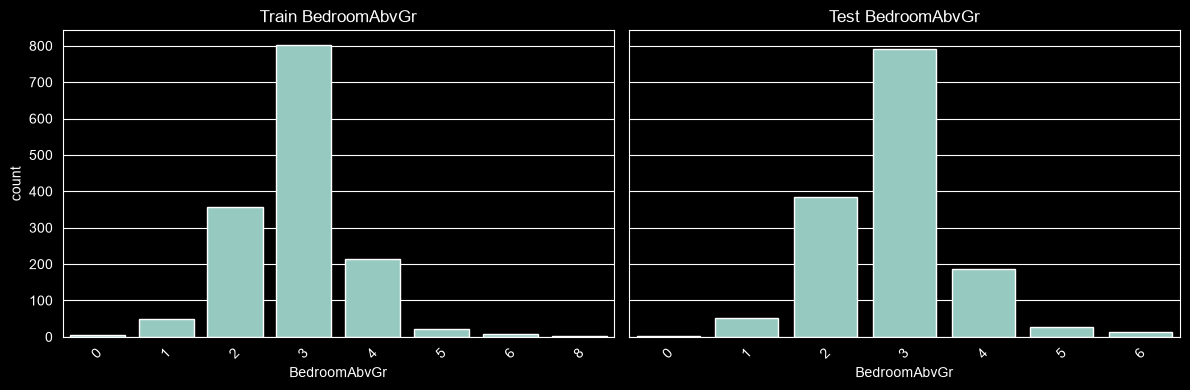

In [2719]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='BedroomAbvGr', ax=axes[0])
axes[0].set_title('Train BedroomAbvGr')

sns.countplot(data=df_test, x='BedroomAbvGr', ax=axes[1])
axes[1].set_title('Test BedroomAbvGr')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Kitchen

In [2720]:
print(df['KitchenAbvGr'].isna().sum())
print(df_test['KitchenAbvGr'].isna().sum())

0
0


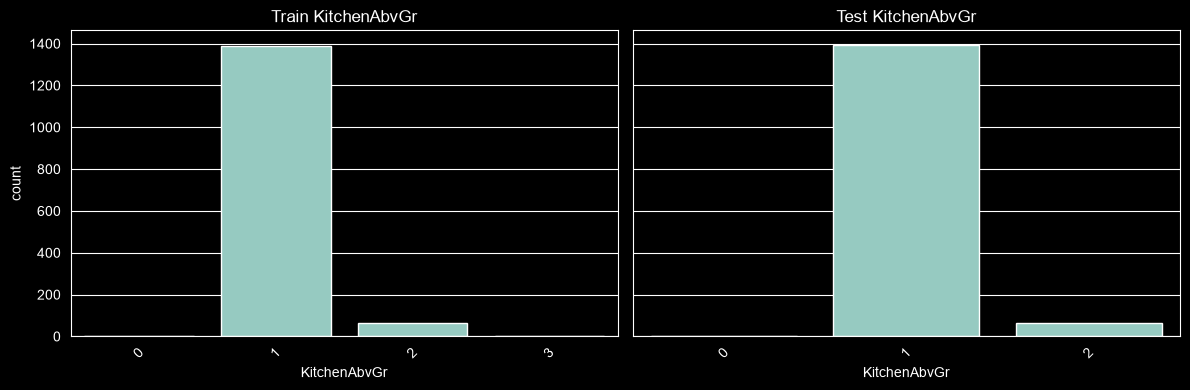

In [2721]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='KitchenAbvGr', ax=axes[0])
axes[0].set_title('Train KitchenAbvGr')

sns.countplot(data=df_test, x='KitchenAbvGr', ax=axes[1])
axes[1].set_title('Test KitchenAbvGr')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2722]:
df['Other_Rms_AbvGrd'] = df['TotRmsAbvGrd'] - df['BedroomAbvGr'] - df['KitchenAbvGr']
df_test['Other_Rms_AbvGrd'] = df_test['TotRmsAbvGrd'] - df_test['BedroomAbvGr'] - df_test['KitchenAbvGr']

KitchenQual

In [2723]:
print(df['KitchenQual'].isna().sum())
print(df_test['KitchenQual'].isna().sum())

0
1


In [2724]:
global_mode = df['KitchenQual'].mode()[0]
neigh_mode = df.groupby('Neighborhood')['KitchenQual'].apply(lambda x: x.mode()[0] if not x.mode().empty else global_mode)

df_test['KitchenQual'] = df_test['KitchenQual'].fillna(df_test['Neighborhood'].map(neigh_mode))

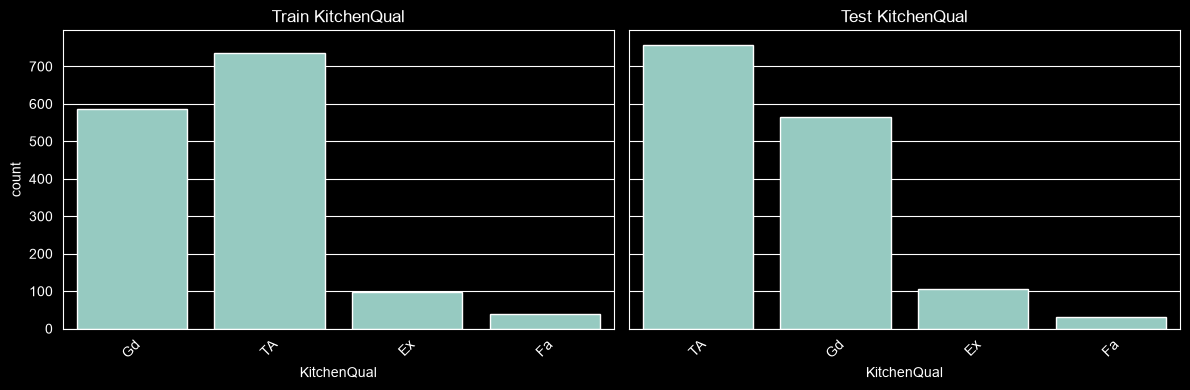

In [2725]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='KitchenQual', ax=axes[0])
axes[0].set_title('Train KitchenQual')

sns.countplot(data=df_test, x='KitchenQual', ax=axes[1])
axes[1].set_title('Test KitchenQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Fireplaces

In [2726]:
print(df['Fireplaces'].isna().sum())
print(df_test['Fireplaces'].isna().sum())

0
0


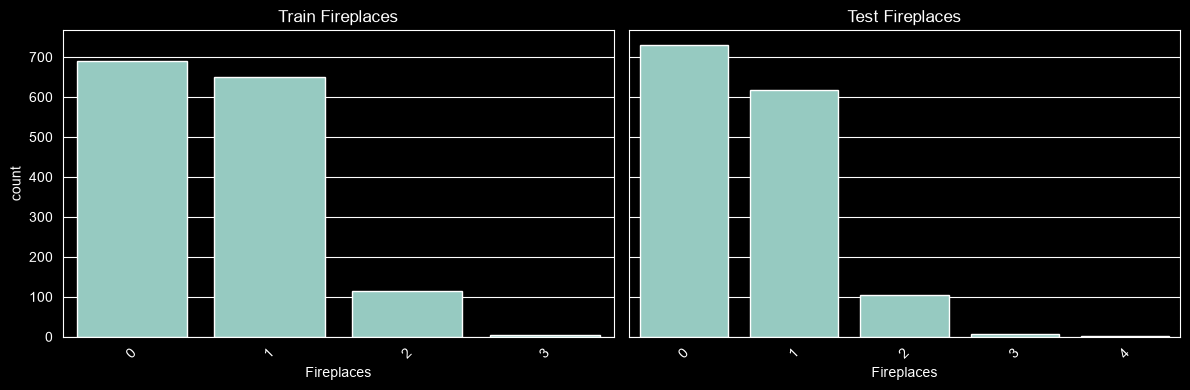

In [2727]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='Fireplaces', ax=axes[0])
axes[0].set_title('Train Fireplaces')

sns.countplot(data=df_test, x='Fireplaces', ax=axes[1])
axes[1].set_title('Test Fireplaces')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2728]:
df['Fireplaces'] = df['Fireplaces'].clip(upper=2)
df_test['Fireplaces'] = df_test['Fireplaces'].clip(upper=2)



FireplaceQu

In [2729]:
print(df['FireplaceQu'].isna().sum())
print(df_test['FireplaceQu'].isna().sum())

690
730


In [2730]:
df['FireplaceQu'] = df['FireplaceQu'].fillna('None')
df_test['FireplaceQu'] = df_test['FireplaceQu'].fillna('None')

df.loc[df['Fireplaces'] == 0, 'FireplaceQu'] = 'None'
df_test.loc[df_test['Fireplaces'] == 0, 'FireplaceQu'] = 'None'

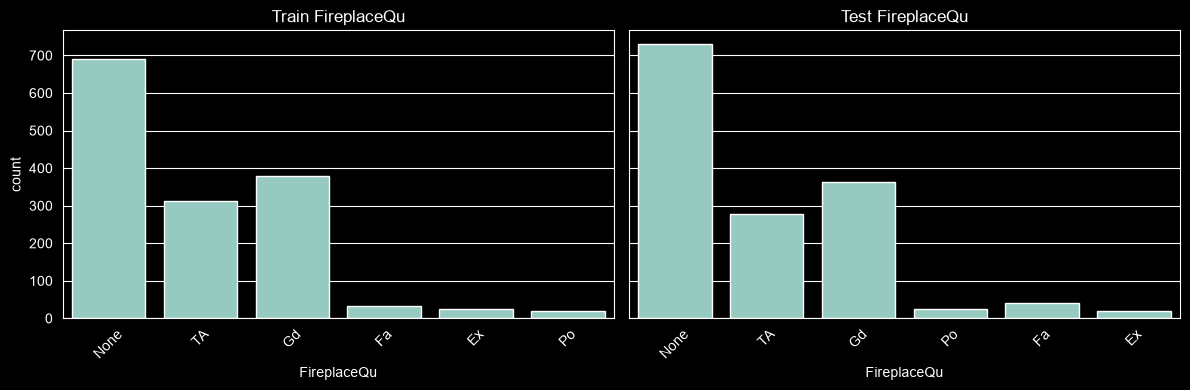

In [2731]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='FireplaceQu', ax=axes[0])
axes[0].set_title('Train FireplaceQu')

sns.countplot(data=df_test, x='FireplaceQu', ax=axes[1])
axes[1].set_title('Test FireplaceQu')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageArea

In [2732]:
print(df['GarageArea'].isna().sum())
print(df_test['GarageArea'].isna().sum())

0
0


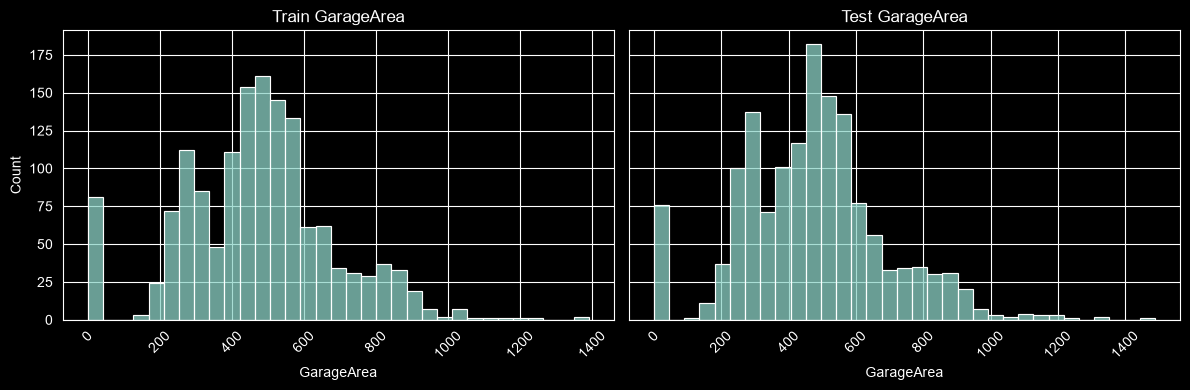

In [2733]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageArea', ax=axes[0])
axes[0].set_title('Train GarageArea')

sns.histplot(data=df_test, x='GarageArea', ax=axes[1])
axes[1].set_title('Test GarageArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageCars

In [2734]:
print(df['GarageCars'].isna().sum())
print(df_test['GarageCars'].isna().sum())

0
0


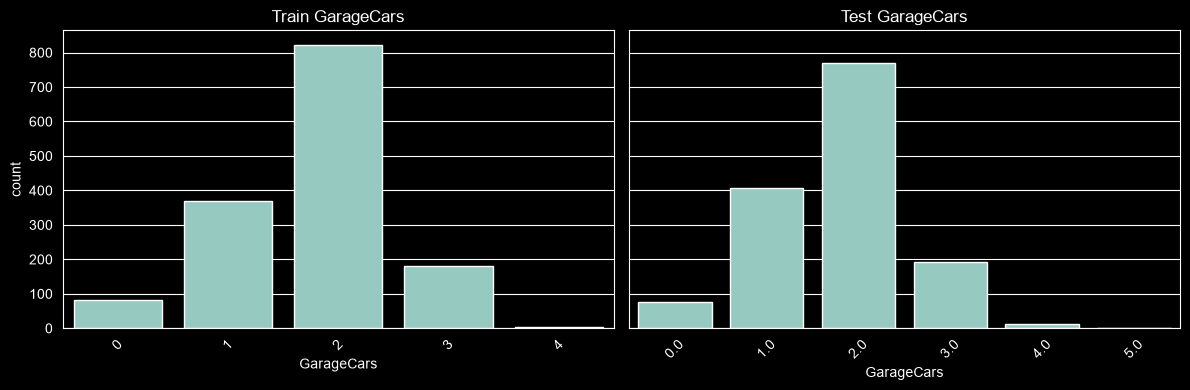

In [2735]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='GarageCars', ax=axes[0])
axes[0].set_title('Train GarageCars')

sns.countplot(data=df_test, x='GarageCars', ax=axes[1])
axes[1].set_title('Test GarageCars')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageQual

In [2736]:
print(df['GarageQual'].isna().sum())
print(df_test['GarageQual'].isna().sum())

0
0


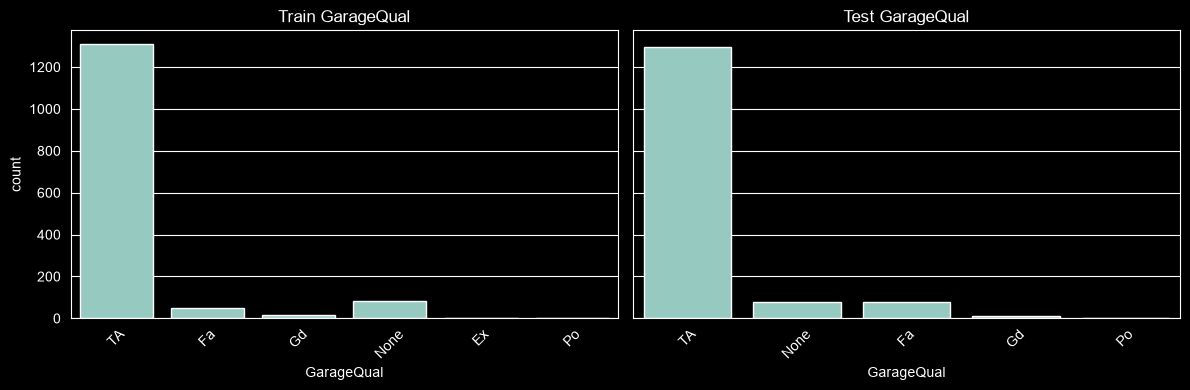

In [2737]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='GarageQual', ax=axes[0])
axes[0].set_title('Train GarageQual')

sns.countplot(data=df_test, x='GarageQual', ax=axes[1])
axes[1].set_title('Test GarageQual')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageType

In [2738]:
print(df['GarageType'].isna().sum())
print(df_test['GarageType'].isna().sum())

0
0


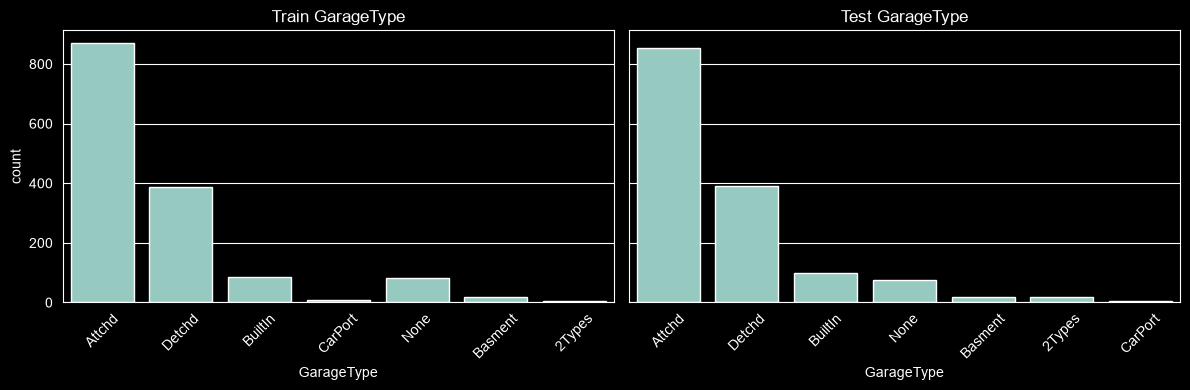

In [2739]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='GarageType', ax=axes[0])
axes[0].set_title('Train GarageType')

sns.countplot(data=df_test, x='GarageType', ax=axes[1])
axes[1].set_title('Test GarageType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageYrBlt

In [2740]:
print(df['GarageYrBlt'].isna().sum())
print(df_test['GarageYrBlt'].isna().sum())

0
0


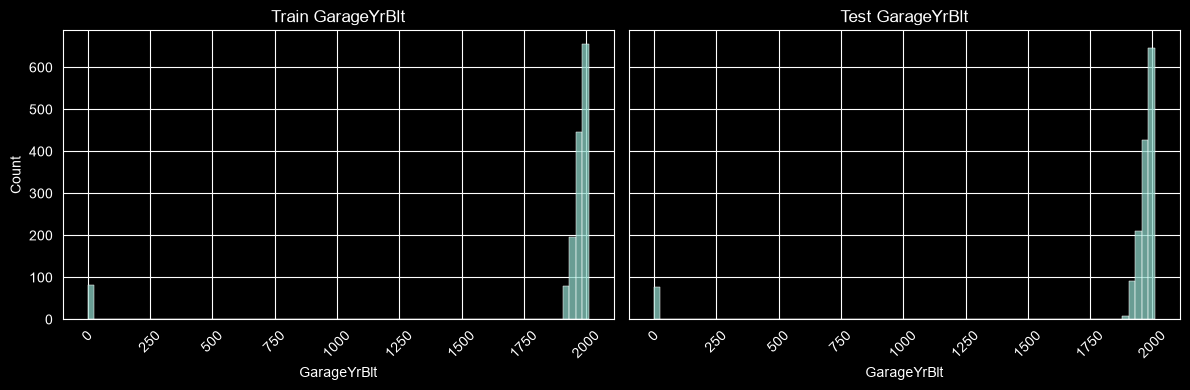

In [2741]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageYrBlt', ax=axes[0])
axes[0].set_title('Train GarageYrBlt')

sns.histplot(data=df_test, x='GarageYrBlt', ax=axes[1])
axes[1].set_title('Test GarageYrBlt')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2742]:
df["Garage_Age"] = np.where(
    df["GarageYrBlt"] > 0,
    np.maximum(0, df["YrSold"] - df["GarageYrBlt"]),
    0,
)
df_test["Garage_Age"] = np.where(
    df_test["GarageYrBlt"] > 0,
    np.maximum(0, df_test["YrSold"] - df_test["GarageYrBlt"]),
    0,
)

df = df.drop(columns=['GarageYrBlt'])
df_test = df_test.drop(columns=['GarageYrBlt'])

GarageFinish

In [2743]:
print(df['GarageFinish'].isna().sum())
print(df_test['GarageFinish'].isna().sum())

0
0


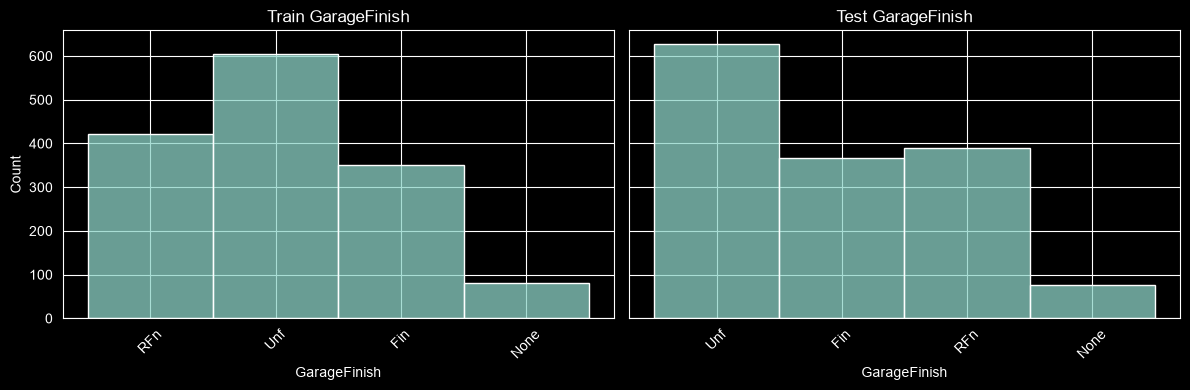

In [2744]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageFinish', ax=axes[0])
axes[0].set_title('Train GarageFinish')

sns.histplot(data=df_test, x='GarageFinish', ax=axes[1])
axes[1].set_title('Test GarageFinish')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

GarageCond

In [2745]:
print(df['GarageCond'].isna().sum())
print(df_test['GarageCond'].isna().sum())

0
0


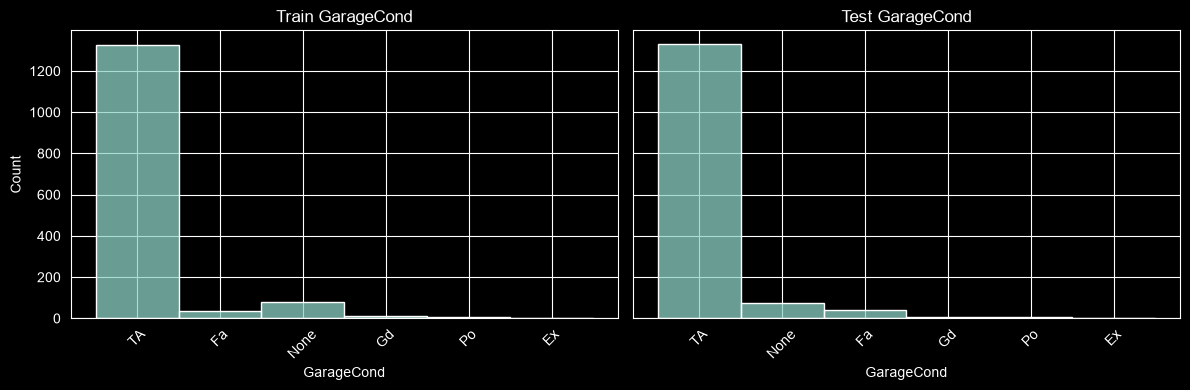

In [2746]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='GarageCond', ax=axes[0])
axes[0].set_title('Train GarageCond')

sns.histplot(data=df_test, x='GarageCond', ax=axes[1])
axes[1].set_title('Test GarageCond')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

PavedDrive

In [2747]:
print(df['PavedDrive'].isna().sum())
print(df_test['PavedDrive'].isna().sum())

0
0


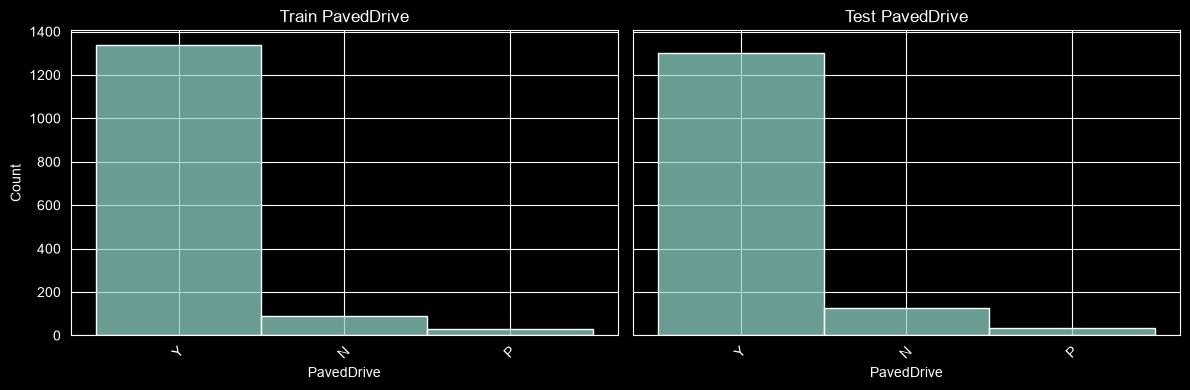

In [2748]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='PavedDrive', ax=axes[0])
axes[0].set_title('Train PavedDrive')

sns.histplot(data=df_test, x='PavedDrive', ax=axes[1])
axes[1].set_title('Test PavedDrive')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

WoodDeckSF

In [2749]:
print(df['WoodDeckSF'].isna().sum())
print(df_test['WoodDeckSF'].isna().sum())

0
0


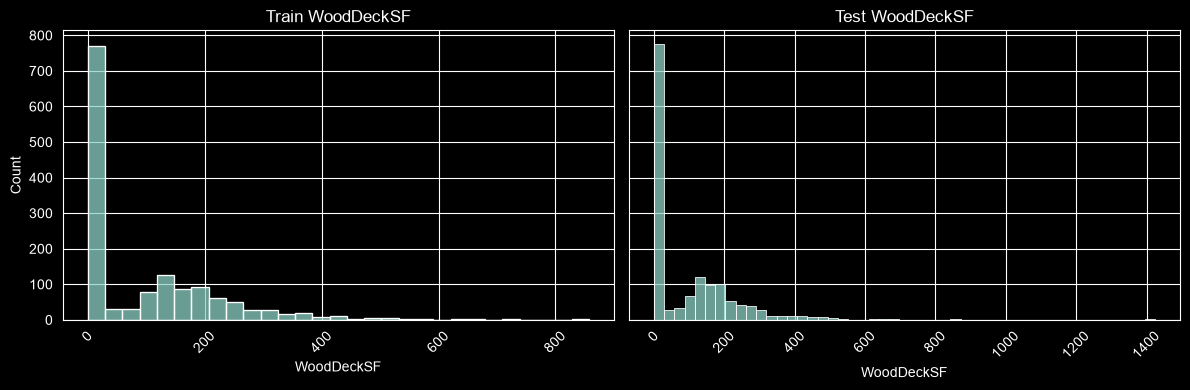

In [2750]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='WoodDeckSF', ax=axes[0])
axes[0].set_title('Train WoodDeckSF')

sns.histplot(data=df_test, x='WoodDeckSF', ax=axes[1])
axes[1].set_title('Test WoodDeckSF')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

OpenPorchSF

In [2751]:
print(df['OpenPorchSF'].isna().sum())
print(df_test['OpenPorchSF'].isna().sum())

0
0


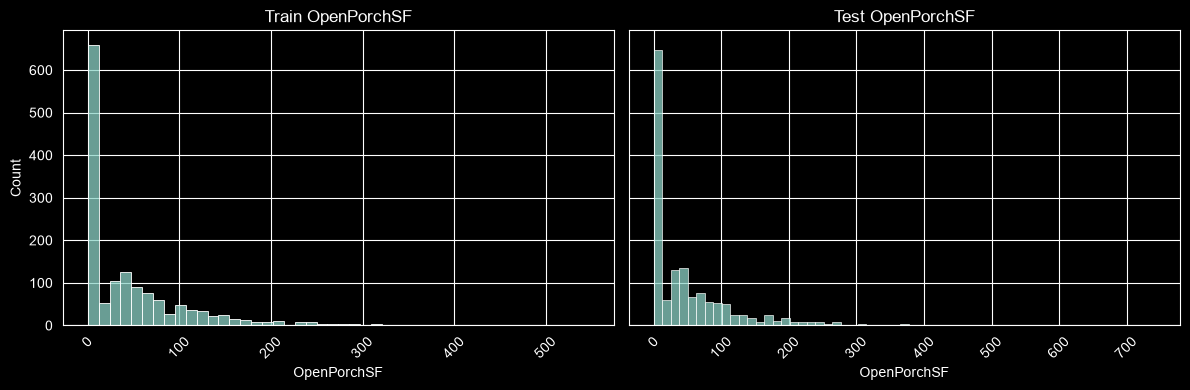

In [2752]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='OpenPorchSF', ax=axes[0])
axes[0].set_title('Train OpenPorchSF')

sns.histplot(data=df_test, x='OpenPorchSF', ax=axes[1])
axes[1].set_title('Test OpenPorchSF')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

EnclosedPorch

In [2753]:
print(df['EnclosedPorch'].isna().sum())
print(df_test['EnclosedPorch'].isna().sum())

0
0


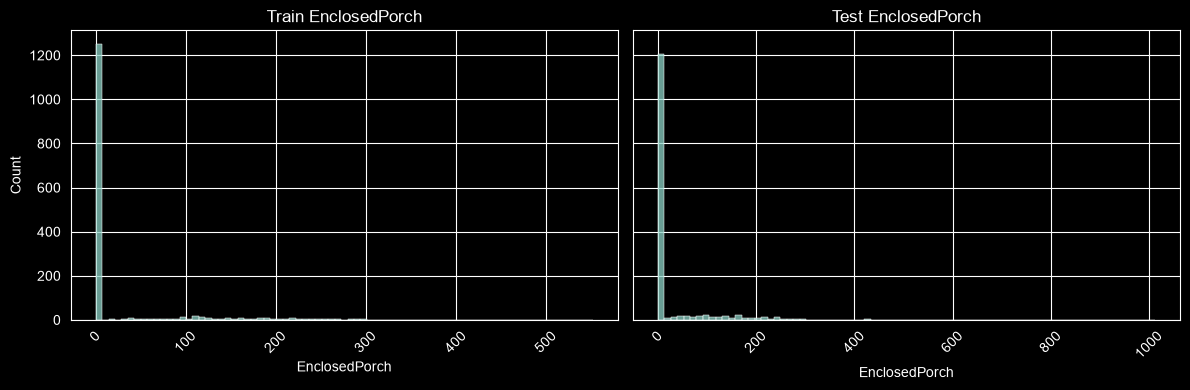

In [2754]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='EnclosedPorch', ax=axes[0])
axes[0].set_title('Train EnclosedPorch')

sns.histplot(data=df_test, x='EnclosedPorch', ax=axes[1])
axes[1].set_title('Test EnclosedPorch')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

3SsnPorch

In [2755]:
print(df['3SsnPorch'].isna().sum())
print(df_test['3SsnPorch'].isna().sum())

0
0


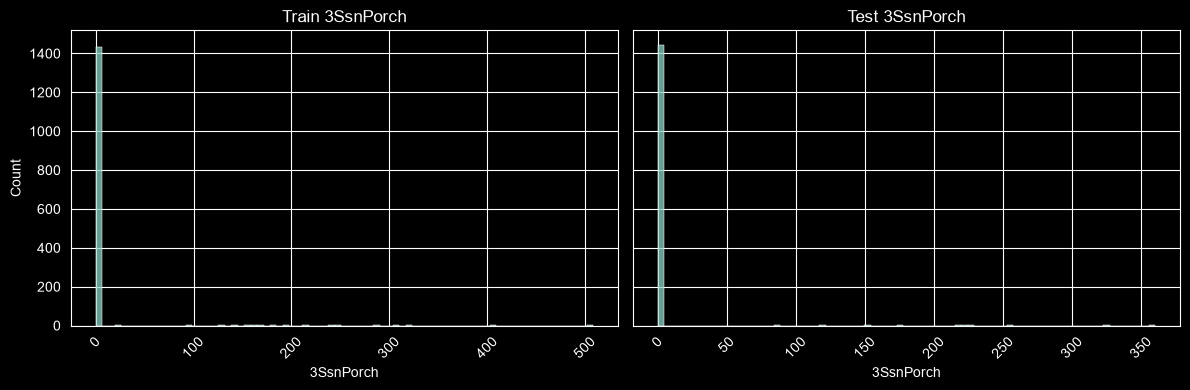

In [2756]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='3SsnPorch', ax=axes[0])
axes[0].set_title('Train 3SsnPorch')

sns.histplot(data=df_test, x='3SsnPorch', ax=axes[1])
axes[1].set_title('Test 3SsnPorch')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

ScreenPorch

In [2757]:
print(df['ScreenPorch'].isna().sum())
print(df_test['ScreenPorch'].isna().sum())

0
0


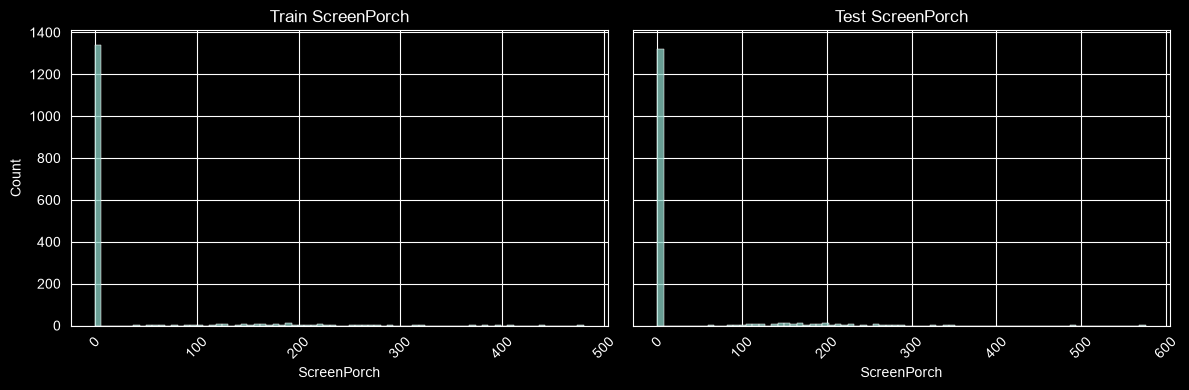

In [2758]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='ScreenPorch', ax=axes[0])
axes[0].set_title('Train ScreenPorch')

sns.histplot(data=df_test, x='ScreenPorch', ax=axes[1])
axes[1].set_title('Test ScreenPorch')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2759]:
porch_cols = ['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']

df['Total_Porch_SF'] = df[porch_cols].sum(axis=1)
df_test['Total_Porch_SF'] = df_test[porch_cols].sum(axis=1)

df = df.drop(columns=['EnclosedPorch', '3SsnPorch', 'ScreenPorch'])
df_test = df_test.drop(columns=['EnclosedPorch', '3SsnPorch', 'ScreenPorch'])

PoolArea

In [2760]:
print(df['PoolArea'].isna().sum())
print(df_test['PoolArea'].isna().sum())

0
0


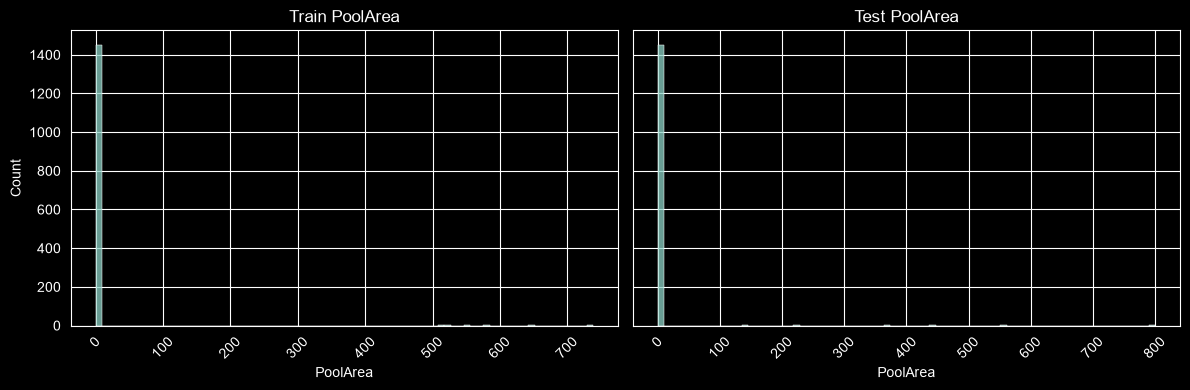

In [2761]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='PoolArea', ax=axes[0])
axes[0].set_title('Train PoolArea')

sns.histplot(data=df_test, x='PoolArea', ax=axes[1])
axes[1].set_title('Test PoolArea')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2762]:
df['Has_Pool'] = (df['PoolArea'] > 0).astype(int)
df_test['Has_Pool'] = (df_test['PoolArea'] > 0).astype(int)

df = df.drop(columns=['PoolArea', 'PoolQC'])
df_test = df_test.drop(columns=['PoolArea', 'PoolQC'])

Fence

In [2763]:
print(df['Fence'].isna().sum())
print(df_test['Fence'].isna().sum())

1177
1169


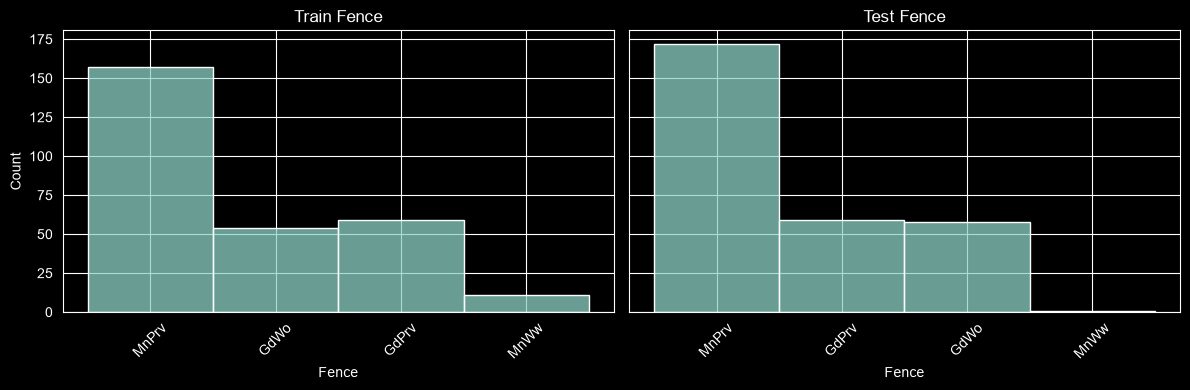

In [2764]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='Fence', ax=axes[0])
axes[0].set_title('Train Fence')

sns.histplot(data=df_test, x='Fence', ax=axes[1])
axes[1].set_title('Test Fence')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2765]:
df['Fence'] = df['Fence'].fillna('None')
df_test['Fence'] = df_test['Fence'].fillna('None')

MiscFeature

In [2766]:
print(df['MiscFeature'].isna().sum())
print(df_test['MiscFeature'].isna().sum())

1404
1408


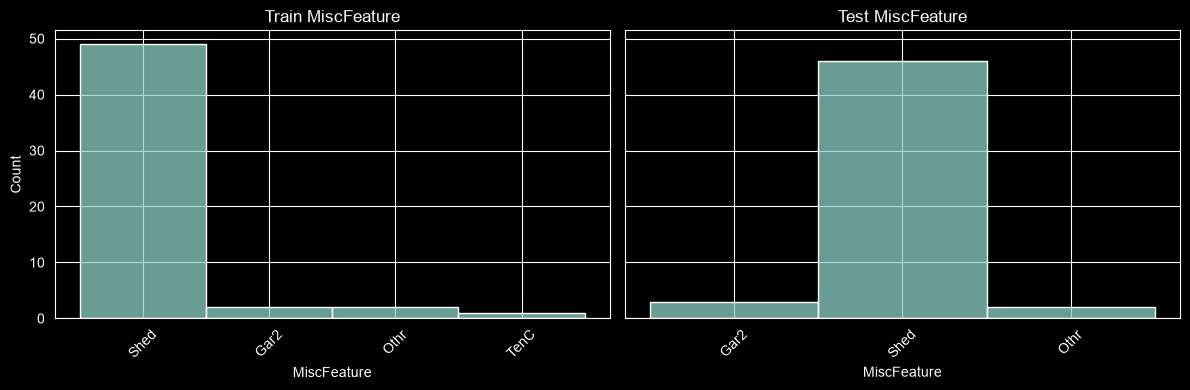

In [2767]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='MiscFeature', ax=axes[0])
axes[0].set_title('Train MiscFeature')

sns.histplot(data=df_test, x='MiscFeature', ax=axes[1])
axes[1].set_title('Test MiscFeature')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2768]:
df['Has_Shed'] = (df['MiscFeature'] == 'Shed').astype(int)
df_test['Has_Shed'] = (df_test['MiscFeature'] == 'Shed').astype(int)

df = df.drop(columns=['MiscFeature', 'MiscVal'])
df_test = df_test.drop(columns=['MiscFeature', 'MiscVal'])

Functional

In [2769]:
print(df['Functional'].isnull().sum())
print(df_test['Functional'].isnull().sum())

0
2


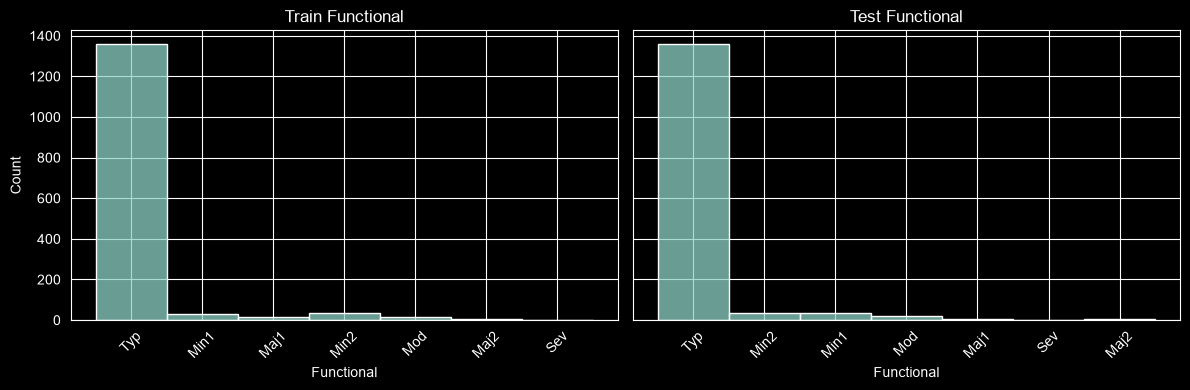

In [2770]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(data=df, x='Functional', ax=axes[0])
axes[0].set_title('Train Functional')

sns.histplot(data=df_test, x='Functional', ax=axes[1])
axes[1].set_title('Test Functional')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2771]:
func_by_nb = df.groupby("Neighborhood")["Functional"].agg(lambda s: s.mode().iloc[0])
func_global = df["Functional"].mode().iloc[0]

df_test["Functional"] = (
    df_test["Functional"]
    .fillna(df_test["Neighborhood"].map(func_by_nb))
    .fillna(func_global)
)

MoSold

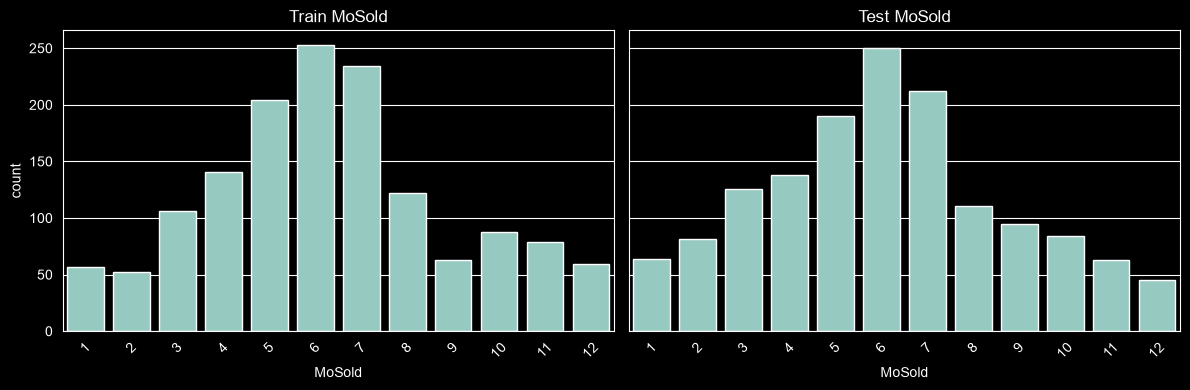

In [2772]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='MoSold', ax=axes[0])
axes[0].set_title('Train MoSold')

sns.countplot(data=df_test, x='MoSold', ax=axes[1])
axes[1].set_title('Test MoSold')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2773]:
print(df['MoSold'].isna().sum())
print(df_test['MoSold'].isna().sum())

0
0


In [2774]:
df['MoSold_Sin'] = np.sin(2 * np.pi * df['MoSold'] / 12)
df['MoSold_Cos'] = np.cos(2 * np.pi * df['MoSold'] / 12)

df_test['MoSold_Sin'] = np.sin(2 * np.pi * df_test['MoSold'] / 12)
df_test['MoSold_Cos'] = np.cos(2 * np.pi * df_test['MoSold'] / 12)

df['Is_Peak_Season'] = df['MoSold'].isin([5, 6, 7]).astype(int)
df_test['Is_Peak_Season'] = df_test['MoSold'].isin([5, 6, 7]).astype(int)

In [2775]:
df = df.drop(columns=['MoSold'])
df_test = df_test.drop(columns=['MoSold'])

YrSold

In [2776]:
print(df['YrSold'].isna().sum())
print(df_test['YrSold'].isna().sum())

0
0


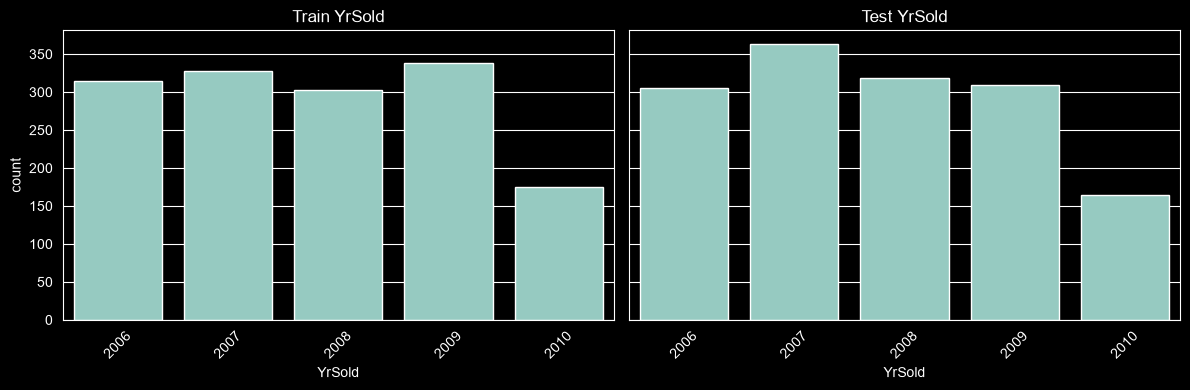

In [2777]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='YrSold', ax=axes[0])
axes[0].set_title('Train YrSold')

sns.countplot(data=df_test, x='YrSold', ax=axes[1])
axes[1].set_title('Test YrSold')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

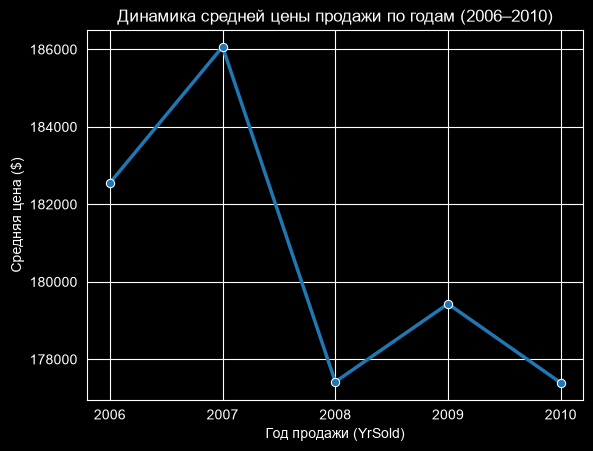

In [2778]:
plt.figure()
yearly_avg = df.groupby('YrSold')['SalePrice'].mean().reset_index()
sns.lineplot(
    data=yearly_avg,
    x='YrSold',
    y='SalePrice',
    marker='o',
    linewidth=2.5,
    color='#1f77b4'
)

plt.title('Динамика средней цены продажи по годам (2006–2010)')
plt.xlabel('Год продажи (YrSold)')
plt.ylabel('Средняя цена ($)')
plt.xticks(yearly_avg['YrSold'].unique())
plt.show()

SaleType

In [2779]:
print(df['SaleType'].isna().sum())
print(df_test['SaleType'].isna().sum())

0
1


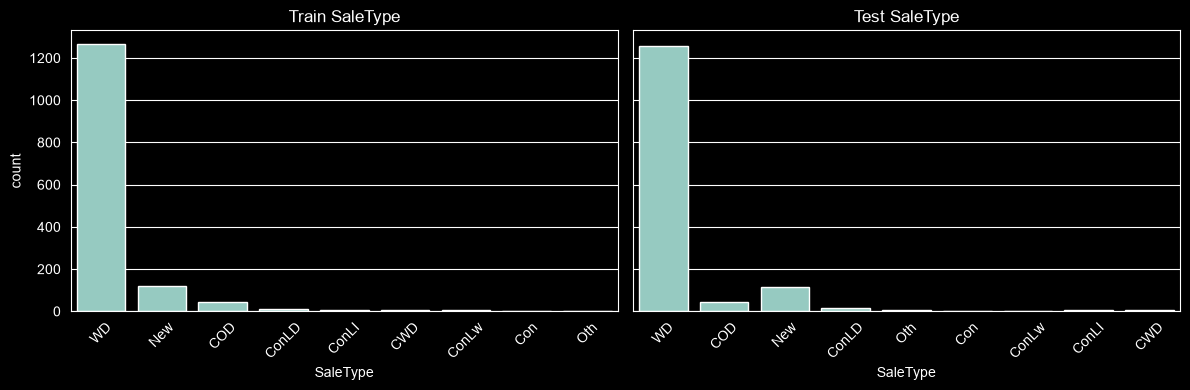

In [2780]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='SaleType', ax=axes[0])
axes[0].set_title('Train SaleType')

sns.countplot(data=df_test, x='SaleType', ax=axes[1])
axes[1].set_title('Test SaleType')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [2781]:
mode_by_year = df.groupby('YrSold')['SaleType'].agg(lambda x: x.mode()[0])
df_test['SaleType'] = df_test['SaleType'].fillna(df_test['YrSold'].map(mode_by_year))

SaleCondition

In [2782]:
print(df['SaleCondition'].isna().sum())
print(df_test['SaleCondition'].isna().sum())

0
0


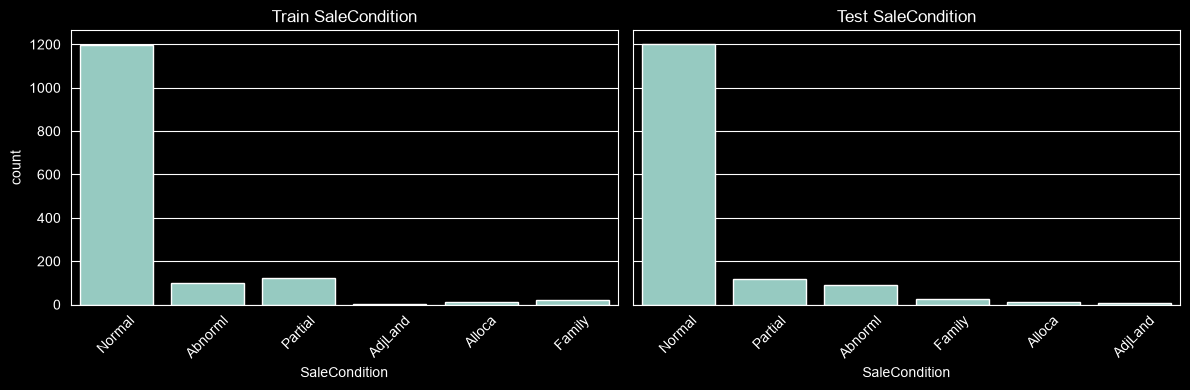

In [2783]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.countplot(data=df, x='SaleCondition', ax=axes[0])
axes[0].set_title('Train SaleCondition')

sns.countplot(data=df_test, x='SaleCondition', ax=axes[1])
axes[1].set_title('Test SaleCondition')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [2784]:
print(df['SalePrice'].isna().sum())

0


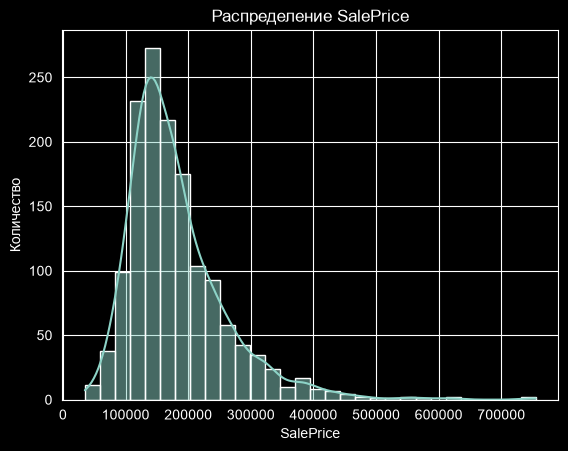

In [2785]:
plt.figure()
sns.histplot(df['SalePrice'], kde=True, bins=30)
plt.title('Распределение SalePrice')
plt.xlabel('SalePrice')
plt.ylabel('Количество')
plt.show()

In [2786]:
df['SalePrice'] = np.log1p(df['SalePrice'])

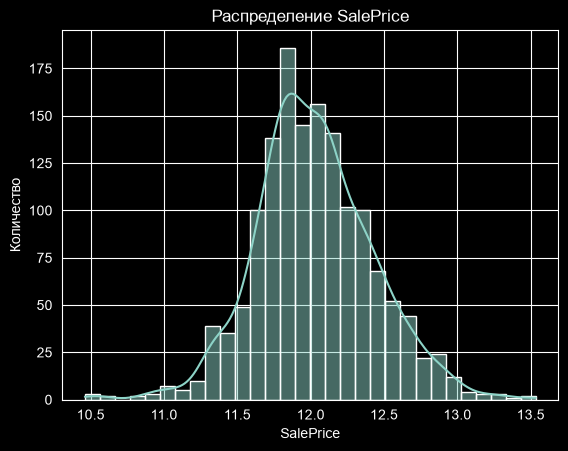

In [2787]:
plt.figure()
sns.histplot(df['SalePrice'], kde=True, bins=30)
plt.title('Распределение SalePrice')
plt.xlabel('SalePrice')
plt.ylabel('Количество')
plt.show()

In [2788]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Alley',
       'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood',
       'BldgType', 'OverallQual', 'OverallCond', 'RoofStyle', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond',
       'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
       'BsmtFinType2', 'TotalBsmtSF', 'HeatingQC', 'CentralAir', '1stFlrSF',
       '2ndFlrSF', 'GrLivArea', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'Fence', 'YrSold',
       'SaleType', 'SaleCondition', 'SalePrice', 'RailRoad', 'NearStreet',
       'NearPark', 'HouseStyle_Group', 'Area_Per_Car', 'House_Age',
       'Remod_Age', 'Is_Remodeled', 'Age_At_Remod', 'Is_Multiple_Exterior',
       'Has_MasVn

In [2789]:
target =['SalePrice']
cols_to_drop = ['Id',
                'SalePrice'
                ]
OHE_cols = ['MSSubClass',
            'MSZoning',
            'Alley',
            'LandContour',
            'LotConfig',
            'BldgType',
            'RoofStyle',
            'HouseStyle_Group',
            'MasVnrType',
            'Foundation',
            'GarageType',
            'SaleType',
            'SaleCondition',


            ]
num_cols = ['LotFrontage',
            'LotArea',
            'MasVnrArea',
            'TotalBsmtSF',
            '1stFlrSF',
            '2ndFlrSF',
            'GrLivArea',
            'BedroomAbvGr',
            'KitchenAbvGr',
            'TotRmsAbvGrd',
            'Fireplaces',
            'Garage_Age',
            'GarageCars',
            'GarageArea',
            'WoodDeckSF',
            'OpenPorchSF',
            'YrSold',
            'Area_Per_Car',
            'House_Age',
            'Remod_Age',
            'Age_At_Remod',
            'Bsmt_Fin_SF',
            'Bsmt_Baths',
            'Total_SF',
            'Avg_Room_SF',
            'AbvGrd_Baths',
            'Total_Baths',
            'Other_Rms_AbvGrd',
            'Total_Porch_SF',
            'MoSold_Sin',
            'MoSold_Cos',
            'OverallQual',
            'OverallCond',
            ]
binary_cols = ['RailRoad',
               'NearStreet',
               'NearPark',
               'Is_Remodeled',
               'Is_Multiple_Exterior',
               'Has_MasVnr',
               'Has_Bsmt',
               'Is_GasA',
               'Has_SBrkr',
               'Has_2ndFlr',
               'Has_LowQualFin',
               'Has_Pool',
               'Has_Shed',
               'Is_Peak_Season',
               'CentralAir',

               ]
target_or_freq_cols = ['Neighborhood','Exterior1st',
            'Exterior2nd',]
ordinal_cols = ['LotShape',
                'LandSlope',
                'ExterQual',
                'ExterCond',
                'BsmtQual',
                'BsmtCond',
                'BsmtExposure',
                'BsmtFinType1',
                'BsmtFinType2',
                'HeatingQC',
                'KitchenQual',
                'Functional',
                'FireplaceQu',
                'GarageFinish',
                'GarageQual',
                'GarageCond',
                'PavedDrive',
                'Fence'
                ]

In [2797]:
df.info()

<class 'pandas.DataFrame'>
Index: 1458 entries, 0 to 1459
Data columns (total 84 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Id                    1458 non-null   int64  
 1   MSSubClass            1458 non-null   str    
 2   MSZoning              1458 non-null   str    
 3   LotFrontage           1458 non-null   float64
 4   LotArea               1458 non-null   float64
 5   Alley                 1458 non-null   str    
 6   LotShape              1458 non-null   str    
 7   LandContour           1458 non-null   str    
 8   LotConfig             1458 non-null   str    
 9   LandSlope             1458 non-null   str    
 10  Neighborhood          1458 non-null   str    
 11  BldgType              1458 non-null   str    
 12  OverallQual           1458 non-null   int64  
 13  OverallCond           1458 non-null   int64  
 14  RoofStyle             1458 non-null   str    
 15  Exterior1st           1458 non-null  

In [2798]:
df.describe()

,Id,LotFrontage,LotArea,OverallQual,OverallCond,MasVnrArea,TotalBsmtSF,CentralAir,1stFlrSF,2ndFlrSF,...,AbvGrd_Baths,Total_Baths,Other_Rms_AbvGrd,Garage_Age,Total_Porch_SF,Has_Pool,Has_Shed,MoSold_Sin,MoSold_Cos,Is_Peak_Season
count,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,...,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1458.000000,1.458000e+03,1.458000e+03,1458.000000
mean,730.251715,69.564472,9.108606,6.093964,5.576132,102.189986,1052.537037,0.934842,1158.851166,345.762003,...,1.754801,2.207476,2.598080,27.718107,180.810014,0.004115,0.033608,1.562118e-03,-3.546225e-01,0.473937
std,421.601532,21.513470,0.513705,1.376369,1.113359,179.109864,414.982320,0.246889,372.039498,435.423924,...,0.634509,0.781341,1.190927,24.946162,156.120838,0.064040,0.180279,6.495584e-01,6.729890e-01,0.499492
min,1.000000,21.000000,7.170888,1.000000,1.000000,0.000000,0.000000,0.000000,334.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000e+00,-1.000000e+00,0.000000
25%,365.250000,60.000000,8.928706,5.000000,5.000000,0.000000,795.250000,1.000000,882.000000,0.000000,...,1.000000,2.000000,2.000000,5.000000,45.000000,0.000000,0.000000,-5.000000e-01,-8.660254e-01,0.000000
50%,730.500000,70.000000,9.156518,6.000000,5.000000,0.000000,991.000000,1.000000,1086.000000,0.000000,...,2.000000,2.000000,2.000000,24.000000,164.000000,0.000000,0.000000,1.224647e-16,-5.000000e-01,0.000000
75%,1094.750000,80.000000,9.358847,7.000000,6.000000,163.750000,1296.750000,1.000000,1390.750000,728.000000,...,2.500000,2.500000,3.000000,46.000000,265.000000,0.000000,0.000000,5.000000e-01,6.123234e-17,1.000000
max,1460.000000,200.000000,12.279537,10.000000,9.000000,1600.000000,3206.000000,1.000000,3228.000000,2065.000000,...,3.500000,6.000000,8.000000,107.000000,1027.000000,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000


In [2790]:
encoded_df = df.copy()
encoded_test_df = df_test.copy()

In [2791]:
from sklearn.preprocessing import OneHotEncoder

num_cols = ["Garage_Age" if col == "GarageYrBlt" else col for col in num_cols]

quality = {"Po": 0, "Fa": 1, "TA": 2, "Gd": 3, "Ex": 4}
quality_none = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
bsmt_fin = {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}

ordinal_maps = {
    "LotShape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "LandSlope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "ExterQual": quality,
    "ExterCond": quality,
    "HeatingQC": quality,
    "KitchenQual": quality,
    "BsmtQual": quality_none,
    "BsmtCond": quality_none,
    "FireplaceQu": quality_none,
    "GarageQual": quality_none,
    "GarageCond": quality_none,
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": bsmt_fin,
    "BsmtFinType2": bsmt_fin,
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
}

y = df["SalePrice"].copy()
encoded_df = df.drop(columns=cols_to_drop).copy()
encoded_test_df = df_test.drop(columns=["Id"]).copy()

for col, mapping in ordinal_maps.items():
    encoded_df[col] = encoded_df[col].map(mapping)
    encoded_test_df[col] = encoded_test_df[col].map(mapping)
    missed = sorted(
        set(df.loc[encoded_df[col].isna(), col].dropna().astype(str))
        | set(df_test.loc[encoded_test_df[col].isna(), col].dropna().astype(str))
    )
    if missed:
        raise ValueError(f"{col}: нет уровня в маппинге: {missed}")

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe_train = pd.DataFrame(
    ohe.fit_transform(encoded_df[OHE_cols]),
    index=encoded_df.index,
    columns=ohe.get_feature_names_out(OHE_cols),
)
ohe_test = pd.DataFrame(
    ohe.transform(encoded_test_df[OHE_cols]),
    index=encoded_test_df.index,
    columns=ohe.get_feature_names_out(OHE_cols),
)

for col in target_or_freq_cols:
    freq = encoded_df[col].value_counts(normalize=True)
    encoded_df[col] = encoded_df[col].map(freq)
    encoded_test_df[col] = encoded_test_df[col].map(freq).fillna(0)

keep = ordinal_cols + num_cols + binary_cols + target_or_freq_cols
X = pd.concat([encoded_df[keep], ohe_train], axis=1)
X_test = pd.concat([encoded_test_df[keep], ohe_test], axis=1)

print(X.shape, X_test.shape, X.isna().sum().sum(), X_test.isna().sum().sum())

(1458, 145) (1459, 145) 0 0


In [2795]:
X.head()

,LotShape,LandSlope,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,HeatingQC,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,3,2,3,2,4,3,1,6,1,4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,3,2,2,2,4,3,4,5,1,4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,2,2,3,2,4,3,2,6,1,4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,2,2,2,2,3,4,1,5,1,3,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
4,2,2,3,2,4,3,3,6,1,4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


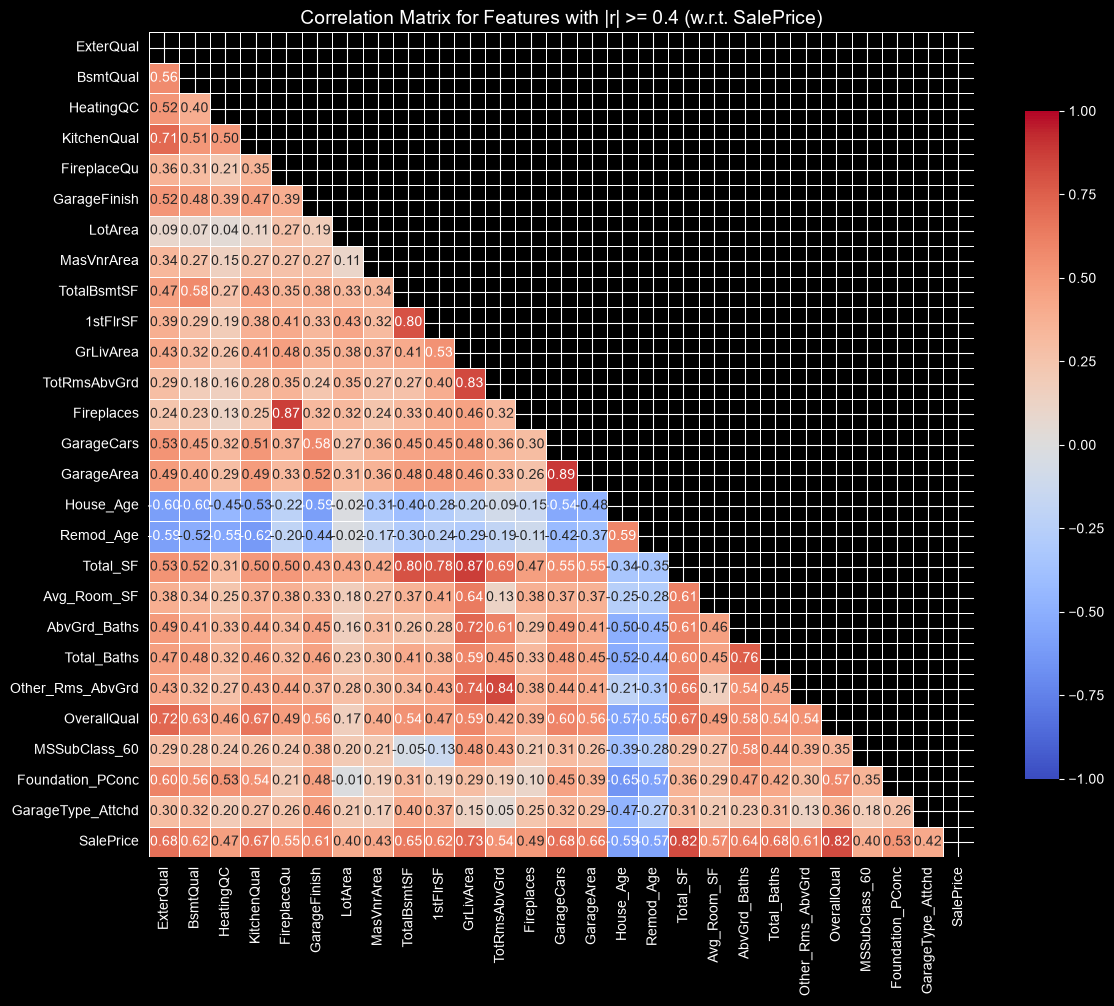

In [2806]:
numeric_X = X.select_dtypes(include=["number"])
target_corr = numeric_X.apply(lambda col: col.corr(y))

threshold = 0.4
top_feature_names = target_corr[np.abs(target_corr) >= threshold].index.tolist()

df_top = numeric_X[top_feature_names].copy()
df_top["SalePrice"] = y

top_corr = df_top.corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(top_corr, dtype=bool))

sns.heatmap(
    top_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8},
)

plt.title(
    f"Correlation Matrix for Features with |r| >= {threshold} (w.r.t. SalePrice)",
    fontsize=14,
)
plt.tight_layout()
plt.show()